# Revisiting the adaptive PRIME threshold: forced pulses, QC and the N45

**Question.** How do the forced-pulse rate, the selectivity of the triggered states and the N45 they can be expected to
produce change with the triggering threshold, once QC is taken into account? And how do alternative threshold rules
compare with the one that ran?

**The rule that ran** (`2_intervention.py`). Every PRIME trial searches from 2.49 s after the previous pulse, one
`process_periodic` call ("tick") every 10 ms. A tick can only trigger when `check_qc()` passes (last 5 pre-stimulus
windows clean and ≥ 80 % of the last 50). When QC passes, the model predicts *p*; the pulse fires at the first tick with
*p* ≥ θ. If nothing fires, the pulse is **forced** at tick 300 (5.5 s after the previous pulse). After each PRIME trial,

θ ← clip(θ + `THRESHOLD_GAIN` · (`TARGET_WAIT` − active wait), `THRESHOLD_MIN`, `THRESHOLD_MAX`),

where *active wait* = search time − QC-blocked time. The rule therefore steers the **active** wait to 0.65 s, while the
forcing deadline counts **wall-clock** time: every QC-blocked tick shortens the budget a trial has to cross θ, and
none of that enters the update.

**What makes it hard.** `prime_predictions.csv` logs *p* at every QC-passing tick, but the trace stops when the trial
triggers. For any threshold below the one in force the outcome is in the data; above it, it has to be modelled.
`TARGET_WAIT_evaluation.ipynb` handled this with Kaplan–Meier bounds on the active wait, which stay wide exactly where
the forced rate starts to matter, and it left QC and the N45 out. Here a validated model of the search fills the gap,
so every rule gets a point estimate (with its share of extrapolation reported).

**Approach.**

1. Rebuild every search tick by tick from the logs (QC pass/fail and *p*), and check the rebuild by replaying the
   rule that ran.
2. Model the search process: the predictor's drifting location, its marginal distribution (from predictions the
   stopping rule did not select: the first tick of every search and the predetermined pulses), its dynamics per block
   (Gaussian state space in normal scores, fitted by likelihood, which is valid on traces stopped by an observed rule),
   and QC (start-of-search failures, run lengths, per-trial onset rates).
3. Check the model where the answer is known. At every logged tick the model gives the probability of crossing the
   threshold at the next tick; summed over a session this should equal the crossings that happened. It does not
   (the fitted model expects too many), so a second, **calibrated** version lowers the simulated predictor by the
   per-block amount that makes the two agree. Both versions are then checked on crossing times of lower levels, forced
   rates at the thresholds that ran, and *censor-and-predict* (stop each trace early, predict when it really crossed),
   where they bracket what happened.
4. Continue each observed trace beyond its trigger with the model (many replicates), so that every trial has an
   outcome under any threshold or rule: exact where the data reach, a range (fitted vs. calibrated) beyond.
5. Translate delivered states into an expected N45 from the single pulses: their N45 against the prediction before the
   pulse. Predetermined pulses (random timing) and all single pulses give different slopes; both are carried through.

**What it cannot do.** Pulses at other moments would change the next trial's pre-stimulus state and the model's
finetuning (and with it the drift of *p*). Every simulation holds the session's own predictions fixed: a direction and an
order of magnitude, not the settled behaviour of a session run that way.

## 0 · Parameters

In [1]:
import numpy as np

SUBJECTS   = ["pilot003", "pilot004", "pilot005"]
SESSION_ID = "ses-prime"
RUN_IDS    = {}                  # e.g. {"pilot005": "105"}; missing: the one run folder with prime/trials_intervention.csv

# ---------------------------------------------------------------- simulation
N_REPLICATES = 200               # continuation draws per trial (Monte-Carlo replicates of each session)
CHUNK        = 50                # replicates simulated at once (memory ~ trials x CHUNK x ticks)
SEED         = 0
ABS_THRESHOLDS = np.round(np.arange(0.45, 0.9501, 0.025), 3)   # fixed probability thresholds
REL_Z          = np.round(np.arange(0.50, 2.5001, 0.125), 3)   # fixed thresholds relative to the predictor's current
                                                                # distribution, in normal-score (z) units
QUANTILE_WINDOW = 50             # rolling-quantile rule: quantile of the last N first-tick predictions
QUANTILES       = [0.70, 0.80, 0.85, 0.90, 0.95]
WAIT_TARGETS    = [0.40, 0.65, 0.90]   # s, for the active-wait rule (as ran) and the wall-wait rule
FORCED_TARGETS  = [0.02, 0.05, 0.10]   # forced-rate controller
FORCED_ETA      = 0.04                 # controller step (probability units per forced trial)
ACTIVE_CAP      = 600            # ticks: hard wall-clock cap when QC-blocked time does not count against the budget

# ---------------------------------------------------------------- model
LOC_INTERIOR_KNOTS = 4           # B-spline of the predictor's location over the 800 intervention trials
TAU_SLOW_MIN       = 0.25        # s: lower bound of the slow component's time constant (else it duplicates the fast one)
QC_MIN_STRATUM     = 15          # QC is modelled per block; strata with fewer trials or blocks use the session-wide fit
GPD_TAIL_Q         = 0.10        # marginal: empirical body, generalised-Pareto tails beyond these quantiles
GPD_XI_RANGE       = (0.0, 0.5)  # tail shape limits: no bounded tails (a bound fitted to ~20 points would map larger
                                 # predictions to z = ±7), no tails heavier than ξ = 0.5
CENSOR_DELTAS      = (0.25, 0.50)  # validation: pseudo-thresholds this far (z units) below each trial's own
PPC_LEVELS         = (1.0, 1.5, 1.75, 2.0)  # validation: z levels whose crossing times are compared
N_BOOT             = 2000        # bootstrap of the amplitude model

# ---------------------------------------------------------------- running
RECOMPUTE   = False              # True: ignore cached fits and simulations
TIME_BUDGET = None               # seconds: stop resumably after this long (None: run everything)
LOOP_ROOT   = None               # None: LOOP_ROOT env var, D:\Linus\Loop, or a folder above this notebook with BIDS + prime
OUT_ROOT    = None               # None: <Loop>/offline_threshold

## 1 · Setup

Loop folder as in the other notebooks. The decider constants are read from `prime/decider/2_intervention.py` with
`ast` (the file is not imported: it loads the TMS driver); section 2 checks them against the logs by replaying the rule.
Nothing is written into `prime/`. Model fits and simulations are cached in `OUT_ROOT/cache`, so re-running the notebook
only redraws the figures.

In [2]:
import ast, functools, hashlib, json, os, pickle, sys, time, warnings, zlib

from pathlib import Path

import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import linalg, optimize, special, stats
from scipy.interpolate import BSpline
from scipy.stats import norm, genpareto, median_abs_deviation

warnings.filterwarnings("ignore")
IN_NOTEBOOK = "ipykernel" in sys.modules
if not IN_NOTEBOOK:
    matplotlib.use("Agg")


def show(df):
    if IN_NOTEBOOK:
        from IPython.display import display
        display(df)
    else:
        with pd.option_context("display.width", 200, "display.max_columns", 40):
            print(df)


INK, INK_2, INK_MUTED, GRID_C, BASE_C, WASH = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#f3f2ee"
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 130, "savefig.bbox": "tight", "font.size": 9, "axes.titlesize": 9.5,
    "axes.labelsize": 9, "axes.edgecolor": BASE_C, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.grid": True, "grid.color": GRID_C, "grid.linewidth": 0.6, "grid.linestyle": "-", "axes.spines.top": False,
    "axes.spines.right": False, "lines.linewidth": 1.6, "lines.solid_capstyle": "round", "legend.frameon": False,
    "legend.fontsize": 8, "axes.titlelocation": "left", "axes.titlecolor": INK, "text.color": INK,
})
# Colours. The three alternative rule families take the first three categorical slots (validated all-pairs, each also
# with its own marker); the current rule is drawn in ink (it is the reference), the oracle frontier in muted ink with a
# direct label. Blocks: ordinal blue ramp (validated). Forced pulses: the status colour "critical".
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
FAMILY_STYLE = {
    "active":    dict(color=INK, marker="o", ls="--", label="active-wait target (current rule)"),
    "wall":      dict(color=BLUE, marker="s", ls="-", label="wall-wait target (QC-aware)"),
    "forced":    dict(color=ORANGE, marker="D", ls="-", label="forced-rate controller"),
    "quantile":  dict(color=AQUA, marker="^", ls="-", label="rolling quantile of first ticks"),
    "relative":  dict(color=INK_MUTED, marker="", ls="-", label="fixed relative z (drift known in advance)"),
}
BLOCK_COLORS = ["#86b6ef", "#5598e7", "#256abf", "#0d366b"]
FORCED_C = "#d03b3b"


def find_loop_root():
    if LOOP_ROOT:
        return Path(LOOP_ROOT)
    env = os.environ.get("LOOP_ROOT")
    for c in ([env] if env else []) + [r"D:\Linus\Loop", str(Path.home() / "mnt" / "Loop")]:
        if c and (Path(c) / "BIDS").is_dir() and (Path(c) / "prime").is_dir():
            return Path(c)
    for d in (Path.cwd(), *Path.cwd().parents):
        if (d / "BIDS").is_dir() and (d / "prime").is_dir():
            return d
    raise FileNotFoundError("Loop folder not found: set LOOP_ROOT")


ROOT = find_loop_root()
PRIME_DIR = ROOT / "prime"
DECIDER = next((d / "2_intervention.py" for d in (PRIME_DIR / "decider", PRIME_DIR) if (d / "2_intervention.py").is_file()), None)
if DECIDER is None:
    raise FileNotFoundError("2_intervention.py not found under prime/")
OUT = Path(OUT_ROOT) if OUT_ROOT else ROOT / "offline_threshold"
if OUT.resolve().is_relative_to(PRIME_DIR.resolve()):
    raise ValueError("OUT_ROOT inside prime/")
CACHE = OUT / "cache"
FIG = OUT / "figures"
for d in (CACHE, FIG):
    d.mkdir(parents=True, exist_ok=True)


def decider_constant(name, src=DECIDER.read_text(encoding="utf-8")):
    for node in ast.parse(src).body:
        if isinstance(node, ast.Assign) and any(getattr(t, "id", None) == name for t in node.targets):
            return ast.literal_eval(node.value)
    raise KeyError(name)


DC = {k: decider_constant(k) for k in ("THRESHOLD_INIT", "THRESHOLD_GAIN", "THRESHOLD_MIN", "THRESHOLD_MAX", "TARGET_WAIT",
                                       "PRIME_MAX_WAIT", "PERIODIC_INTERVAL", "TRIGGER_OFFSET", "QC_RECENT_WINDOWS",
                                       "QC_HISTORY_WINDOWS", "QC_MIN_GOOD_FRACTION")}
TICK = float(DC["PERIODIC_INTERVAL"])
T0_START = time.time()


class BudgetExceeded(RuntimeError):
    pass


def read_cache(path):
    """A cached result, or None when it is missing, unreadable (e.g. written with another numpy version) or RECOMPUTE."""
    if RECOMPUTE or not path.is_file() or path.stat().st_size == 0:
        return None
    try:
        return pickle.loads(path.read_bytes())
    except Exception as e:
        print(f"cache {path.name} not readable ({type(e).__name__}): recomputing")
        return None


def check_budget(what=""):
    if TIME_BUDGET is not None and time.time() - T0_START > TIME_BUDGET:
        raise BudgetExceeded(f"time budget reached before {what}; run again to continue from the cache")


def cache_key(*parts):
    return hashlib.sha1(json.dumps([str(p) for p in parts]).encode()).hexdigest()[:10]


MODEL_TAG = cache_key(SESSION_ID, RUN_IDS, LOC_INTERIOR_KNOTS, GPD_TAIL_Q, GPD_XI_RANGE, TAU_SLOW_MIN, QC_MIN_STRATUM,
                      "v4")                                                       # cache key of everything model-based




print(f"Loop folder : {ROOT}")
print(f"decider     : {DECIDER.relative_to(ROOT)}  (read only)")
print(f"results     : {OUT}")
print("constants   : " + ", ".join(f"{k} {v}" for k, v in DC.items()))

Loop folder : /sessions/rcw-01f4pyjsylaswjyygbnhc7k3/mnt/Loop
decider     : prime/decider/2_intervention.py  (read only)
results     : /sessions/rcw-01f4pyjsylaswjyygbnhc7k3/mnt/Loop/offline_threshold
constants   : THRESHOLD_INIT 0.75, THRESHOLD_GAIN 0.02, THRESHOLD_MIN 0.5, THRESHOLD_MAX 0.95, TARGET_WAIT 0.65, PRIME_MAX_WAIT 5.5, PERIODIC_INTERVAL 0.01, TRIGGER_OFFSET 0.01, QC_RECENT_WINDOWS 5, QC_HISTORY_WINDOWS 50, QC_MIN_GOOD_FRACTION 0.8


## 2 · The sessions, tick by tick

For each PRIME trial (triplets and singles search the same way) the search is rebuilt on a 10 ms grid from
`prime_predictions.csv`: an attempt is a QC-passing tick, so its tick index is `attempt − 1 + qc_failures_so_far`, and
every tick before the trigger without an attempt was blocked by QC. Tick 0 is the first `process_periodic` call after the
500 ms QC warm-up; a trial is forced at the tick where `reference_time > max_time − TRIGGER_OFFSET − interval/2`.

A few searches at the start of a block logged a trigger and then started again from attempt 1 without a pulse in
between (the trial's `search_time` and `qc_failures` belong to the second search); only the last search is kept.

Checks: the rebuilt QC failures equal the logged `qc_failures`; every forced trial ends at the same tick; replaying
`update_threshold()` from the logged `search_time` and `qc_failures` gives the logged `threshold` column.

In [3]:
def logit(p):
    p = np.clip(np.asarray(p, float), 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


def expit(x):
    return 1 / (1 + np.exp(-np.asarray(x, float)))


def session_dir(subject):
    ses = ROOT / "BIDS" / f"sub-{subject}" / SESSION_ID
    run = RUN_IDS.get(subject)
    if run is None:
        runs = sorted({p.parent.parent.name for p in ses.glob("*/prime/trials_intervention.csv")})
        if len(runs) != 1:
            raise FileNotFoundError(f"expected one run folder with prime/trials_intervention.csv in {ses}, found {runs}")
        run = runs[0]
    return ses / str(run) / "prime"


def replay_update(search_time, qc_failures, theta0, target, gain, lo, hi, wait="active"):
    """The decider's update_threshold() over a sequence of PRIME trials; returns the threshold in force per trial."""
    th = np.empty(len(search_time) + 1); th[0] = theta0
    for n, (st, qf) in enumerate(zip(search_time, qc_failures)):
        w = max(0.0, st - qf * TICK) if wait == "active" else st
        th[n + 1] = min(max(th[n] + gain * (target - w), lo), hi)
    return th[:-1]


def load_session(subject):
    od = session_dir(subject)
    T = pd.read_csv(od / "trials_intervention.csv")
    for c in ("is_forced", "postprocessing_failed", "preprocessing_failed"):
        T[c] = T[c].astype(str).str.lower().eq("true")
    iv = T[T.stage.str.startswith("intervention_block_")].reset_index(drop=True)
    iv["g"] = np.arange(len(iv))
    iv["block"] = iv.stage.str.rsplit("_", n=1).str[1].astype(int)
    iv["key"] = iv.stage + "_" + iv.trial_in_stage.astype(str)
    iv["iti_prev"] = iv.groupby("stage").pulse_time.diff()
    P = pd.read_csv(od / "prime_predictions.csv")
    P["key"] = P.stage + "_" + P.trial_in_stage.astype(str)
    P["tick"] = (P.attempt - 1) + P.qc_failures_so_far
    # A search that restarted (attempt back to 1) keeps only its last segment: the one whose pulse was delivered.
    seg = (P.groupby("key", sort=False).attempt.diff() <= 0).astype(int).groupby(P.key).cumsum()
    restarted = sorted(P.key[seg > 0].unique())
    P = P[seg == seg.groupby(P.key).transform("max")]
    P["is_forced_row"] = P.forced.astype(str).str.lower().eq("true")
    pr = iv[iv.condition.isin(["prime_triplet", "prime_single_pulse"])].reset_index(drop=True)
    pr["t_search_start"] = (pr.pulse_time - pr.trial_start_time) - pr.search_time
    groups = dict(tuple(P.groupby("key")))
    deadline = int(round((DC["PRIME_MAX_WAIT"] - DC["TRIGGER_OFFSET"] - pr.t_search_start.median()) / TICK))
    N, K = len(pr), deadline
    Y = np.full((N, K), np.nan); QC = np.zeros((N, K), bool); stop = np.zeros(N, int)
    for i, r in pr.iterrows():
        g = groups[r.key]
        ok = ~g.is_forced_row
        t = g.tick[ok].astype(int).values
        Y[i, t] = logit(g.probability[ok].values); QC[i, t] = True
        stop[i] = int(g.tick[g.is_forced_row].iloc[0]) if r.is_forced else int(t.max())
    obs_end = np.where(pr.is_forced.values, K - 1, stop)        # last observed tick
    checks = {}
    qcf = np.array([(~QC[i, :stop[i]]).sum() if not pr.is_forced[i] else (~QC[i, :K]).sum() for i in range(N)])
    checks["QC failures rebuilt = logged"] = (qcf == pr.qc_failures.values.astype(int)).all()
    checks["forced trials end at the deadline tick"] = bool((stop[pr.is_forced.values] == K).all())
    checks["search starts at the same time in every trial"] = bool(pr.t_search_start.std() < 1e-3)
    th = replay_update(pr.search_time.values, pr.qc_failures.values, DC["THRESHOLD_INIT"], DC["TARGET_WAIT"],
                       DC["THRESHOLD_GAIN"], DC["THRESHOLD_MIN"], DC["THRESHOLD_MAX"])
    checks["update_threshold() replay = logged threshold (max |diff| < 1e-9)"] = bool(np.max(np.abs(th - pr.threshold.values)) < 1e-9)
    pdm = iv[iv.condition == "predetermined_single"].reset_index(drop=True)
    return dict(subject=subject, dir=od, iv=iv, pr=pr, pdm=pdm, Y=Y, QC=QC, stop=stop, obs_end=obs_end, K=K, restarted=restarted,
                t_search_start=float(pr.t_search_start.median()), checks=checks,
                latency=float(np.median(pr.search_time.values - (stop + 1) * TICK)))


SESS = {}
rows = []
for s in SUBJECTS:
    S = load_session(s)
    SESS[s] = S
    pr = S["pr"]
    rows.append({"session": s, "PRIME trials": len(pr), "forced": int(pr.is_forced.sum()),
                 "forced %": round(100 * pr.is_forced.mean(), 1), "deadline tick": S["K"],
                 "searches restarted (last segment kept)": ", ".join(k.replace("intervention_block_", "block ") for k in S["restarted"]) or "none",

                 "search starts (s after previous pulse)": round(S["t_search_start"], 3),
                 "ticks with a prediction": int(np.isfinite(S["Y"]).sum()),
                 **{k: ("ok" if v else "FAILED") for k, v in S["checks"].items()}})
show(pd.DataFrame(rows).set_index("session").T)
assert all(all(S["checks"].values()) for S in SESS.values()), "a rebuild check failed"

session,pilot003,pilot004,pilot005
PRIME trials,720,720,720
forced,50,78,23
forced %,6.9,10.8,3.2
deadline tick,300,300,300
searches restarted (last segment kept),none,"block 3_0, block 4_0",block 4_0
search starts (s after previous pulse),2.49,2.49,2.49
ticks with a prediction,47925,47920,47925
QC failures rebuilt = logged,ok,ok,ok
forced trials end at the deadline tick,ok,ok,ok
search starts at the same time in every trial,ok,ok,ok


## 3 · What QC does to the search

*Wall wait* is the search time (every tick counts), *active wait* only the QC-passing ticks, i.e. what the rule
steers. A trial is forced when the wall wait reaches 3.0 s. Below: how much of each search QC blocks, how often a search
starts blocked, how forced trials differ, and what the active-wait target does to the inter-trial interval.

,pilot003,pilot004,pilot005
searches starting with QC blocked (%),22.639,27.778,8.056
trials with any QC block (%),35.000,58.750,28.472
"QC-blocked time per trial, mean (s)",0.224,0.354,0.061
in forced trials (s),0.658,1.144,0.253
in triggered trials (s),0.192,0.258,0.055
share of the 3.0 s budget lost to QC in forced trials (%),21.920,38.150,8.449
"wall wait, mean (s)",0.891,1.021,0.727
"active wait, mean (s) [rule target 0.65]",0.666,0.667,0.666
forced among trials starting blocked (%),7.975,12.000,5.172
forced among trials starting clean (%),6.643,10.385,3.021


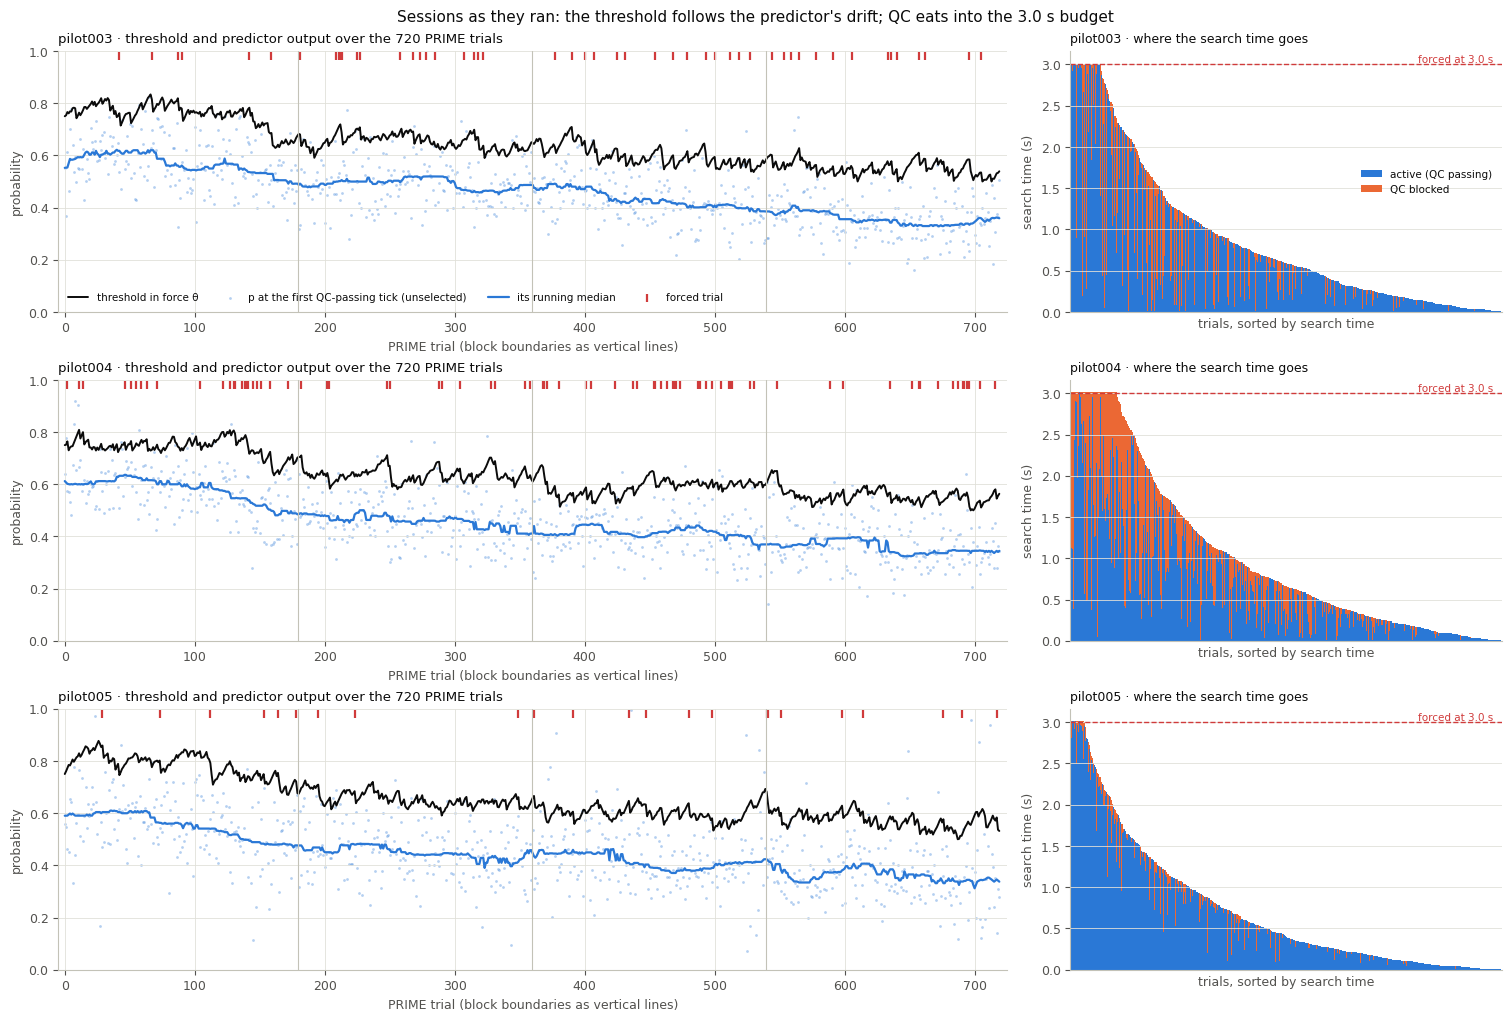

In [4]:
def qc_summary(S):
    pr = S["pr"]; QC = S["QC"]
    first_fail = ~QC[:, 0]
    wall = pr.search_time.values
    qc_time = pr.qc_failures.values * TICK
    active = np.maximum(0, wall - qc_time)
    pd_iti = S["pdm"].iti_prev.dropna()
    pr_iti = pr.iti_prev.dropna()
    f = pr.is_forced.values
    return {
        "searches starting with QC blocked (%)": 100 * first_fail.mean(),
        "trials with any QC block (%)": 100 * (qc_time > 0).mean(),
        "QC-blocked time per trial, mean (s)": qc_time.mean(),
        "  in forced trials (s)": qc_time[f].mean(),
        "  in triggered trials (s)": qc_time[~f].mean(),
        "share of the 3.0 s budget lost to QC in forced trials (%)": 100 * qc_time[f].mean() / (S["K"] * TICK),
        "wall wait, mean (s)": wall.mean(),
        "active wait, mean (s)  [rule target 0.65]": active.mean(),
        "forced among trials starting blocked (%)": 100 * f[first_fail].mean(),
        "forced among trials starting clean (%)": 100 * f[~first_fail].mean(),
        "ITI before PRIME pulses, mean (s)": pr_iti.mean(),
        "ITI before predetermined pulses, mean (s)": pd_iti.mean(),
    }


show(pd.DataFrame({s: qc_summary(SESS[s]) for s in SUBJECTS}).round(3))


def fig_session_overview():
    fig, axes = plt.subplots(len(SUBJECTS), 2, figsize=(15, 3.1 * len(SUBJECTS) + 0.8), squeeze=False,
                             gridspec_kw=dict(width_ratios=[2.2, 1]), layout="constrained")
    for i, s in enumerate(SUBJECTS):
        S = SESS[s]; pr = S["pr"]
        ax = axes[i, 0]
        n = np.arange(len(pr))
        ax.plot(n, pr.threshold, color=INK, lw=1.4, label="threshold in force θ")
        first = np.array([expit(S["Y"][j, np.argmax(S["QC"][j])]) if S["QC"][j].any() else np.nan for j in n])
        ax.scatter(n, first, s=4, color=BLUE, alpha=0.35, lw=0, label="p at the first QC-passing tick (unselected)")
        sm = pd.Series(first).rolling(41, center=True, min_periods=10).median()
        ax.plot(n, sm, color=BLUE, lw=1.6, label="its running median")
        f = pr.is_forced.values
        ax.scatter(n[f], np.full(f.sum(), 0.98), marker="|", s=40, color=FORCED_C, label="forced trial")
        for b in range(2, 5):
            ax.axvline(np.argmax(pr.block.values == b) - 0.5, color=BASE_C, lw=0.8)
        ax.set_ylim(0, 1.0); ax.set_xlim(-5, len(pr) + 5)
        ax.set_xlabel("PRIME trial (block boundaries as vertical lines)")
        ax.set_ylabel("probability"); ax.set_title(f"{s} · threshold and predictor output over the {len(pr)} PRIME trials")
        if i == 0:
            ax.legend(loc="lower left", ncol=4, fontsize=7.5)
        ax = axes[i, 1]
        qc_t = pr.qc_failures.values * TICK
        act = np.maximum(0, pr.search_time.values - qc_t)
        order = np.argsort(pr.search_time.values)[::-1]
        x = np.arange(len(pr))
        ax.bar(x, act[order], width=1.0, color=BLUE, lw=0, label="active (QC passing)")
        ax.bar(x, qc_t[order], bottom=act[order], width=1.0, color=ORANGE, lw=0, label="QC blocked")
        ax.axhline(S["K"] * TICK, color=FORCED_C, ls="--", lw=1.0)
        ax.text(len(pr) * 0.98, S["K"] * TICK, "forced at 3.0 s", ha="right", va="bottom", fontsize=7.5, color=FORCED_C)
        ax.set_xlim(-1, len(pr)); ax.set_xticks([])
        ax.set_ylabel("search time (s)"); ax.set_xlabel("trials, sorted by search time")
        ax.set_title(f"{s} · where the search time goes", fontsize=9)
        if i == 0:
            ax.legend(loc="center right", fontsize=7.5)
    fig.suptitle("Sessions as they ran: the threshold follows the predictor's drift; QC eats into the 3.0 s budget", fontsize=11)
    fig.savefig(FIG / "1_sessions_overview.png")
    plt.show() if IN_NOTEBOOK else plt.close(fig)


fig_session_overview()

## 4 · A model of the search

### 4.1 The predictor's distribution, from predictions nobody selected

Within a trial the logged predictions are selected (the trace stops at the first high value), so their distribution
is biased. Two kinds of prediction are not: the **first QC-passing tick of every search** (it happens before the
threshold can act; QC does not depend on *p*) and the **predetermined pulses** (fixed timing). Both should come from the
same distribution if *p* is stationary across the 2.5–5.5 s window; the KS test below checks that.

From these unselected predictions (logit scale): a smooth **location** over the session (B-spline), and per block a
**scale** (MAD) and the **shape** of the standardised residuals (empirical body, generalised-Pareto tails). Every
prediction is then mapped to a normal score z = Φ⁻¹(G((logit p − location)/scale)). In z units, "the 90th percentile of
the predictor's current output" is z = 1.28 at any point in the session, whatever the drift.

In [5]:
def bspline_basis(g, n_g, n_interior):
    x = np.ascontiguousarray(np.asarray(g, float).ravel())
    inner = np.linspace(0, n_g - 1, n_interior + 2)
    t = np.r_[[inner[0]] * 3, inner, [inner[-1]] * 3]
    return BSpline.design_matrix(np.clip(x, inner[0], inner[-1]), t, 3).toarray()


def gpd_fit(excess, xi_range=GPD_XI_RANGE):
    """Generalised-Pareto fit (location 0) with the shape limited to xi_range (scale refitted at the limit)."""
    c, _, sc = genpareto.fit(excess, floc=0)
    if not xi_range[0] <= c <= xi_range[1]:
        c = float(np.clip(c, *xi_range))
        sc = float(np.mean(excess)) if c == 0 else genpareto.fit(excess, fc=c, floc=0)[2]
    return (c, 0, sc)


class Marginal:
    """Distribution of standardised residuals: ECDF in the body, generalised-Pareto tails beyond q_tail / 1 - q_tail."""
    def __init__(self, r, q_tail=GPD_TAIL_Q):
        r = np.sort(np.asarray(r, float)); n = len(r)
        self.r, self.F = r, (np.arange(1, n + 1) - 0.5) / n
        self.q_lo, self.q_hi = q_tail, 1 - q_tail
        self.u_lo, self.u_hi = np.quantile(r, self.q_lo), np.quantile(r, self.q_hi)
        self.hi = gpd_fit(r[r > self.u_hi] - self.u_hi)
        self.lo = gpd_fit(self.u_lo - r[r < self.u_lo])


    def cdf(self, x):
        x = np.asarray(x, float)
        out = np.interp(x, self.r, self.F)
        out = np.where(x > self.u_hi, self.q_hi + (1 - self.q_hi) * genpareto.cdf(x - self.u_hi, *self.hi), out)
        out = np.where(x < self.u_lo, self.q_lo * genpareto.sf(self.u_lo - x, *self.lo), out)
        return np.clip(out, 1e-12, 1 - 1e-12)

    def ppf(self, q):
        q = np.asarray(q, float)
        out = np.interp(q, self.F, self.r)
        out = np.where(q > self.q_hi, self.u_hi + genpareto.ppf(np.clip((q - self.q_hi) / (1 - self.q_hi), 0, 1 - 1e-12), *self.hi), out)
        out = np.where(q < self.q_lo, self.u_lo - genpareto.ppf(np.clip(1 - q / self.q_lo, 0, 1 - 1e-12), *self.lo), out)
        return out


def unselected(S):
    """Predictions the stopping rule did not select: first QC-passing tick of each search, predetermined pulses."""
    N = len(S["stop"])
    has = S["QC"].any(axis=1)
    k0 = np.argmax(S["QC"], axis=1)
    xf = np.where(has, S["Y"][np.arange(N), k0], np.nan)
    pdm = S["pdm"]
    xp = logit(pdm.prediction_probability.values)
    df = pd.DataFrame({"x": np.r_[xf, xp], "g": np.r_[S["pr"].g.values, pdm.g.values],
                       "source": ["first tick"] * N + ["predetermined"] * len(pdm),
                       "wait": np.r_[S["t_search_start"] + k0 * TICK, pdm.iti_prev.values]})
    return df[np.isfinite(df.x)].reset_index(drop=True)


def fit_marginals(S):
    U = unselected(S); n_g = len(S["iv"])
    B = bspline_basis(U.g, n_g, LOC_INTERIOR_KNOTS)
    coef, *_ = np.linalg.lstsq(B, U.x.values, rcond=None)
    loc = lambda g, coef=coef: (bspline_basis(g, n_g, LOC_INTERIOR_KNOTS) @ coef).reshape(np.shape(g))
    d = U.x.values - loc(U.g.values)
    block_of_g = S["iv"].block.values
    U["block"] = block_of_g[U.g.values]
    blocks = {}
    for b in range(1, 5):
        m = (U.block == b).values
        sc = median_abs_deviation(d[m], scale="normal")
        blocks[b] = dict(scale=sc, G=Marginal(d[m] / sc), n=int(m.sum()))
    M = dict(loc=loc, blocks=blocks, U=U, coef=coef, block_of_g=block_of_g)
    U["z"] = to_z(U.x.values, U.g.values, M)
    return M


def to_z(x, g, M):
    """Normal score of logit predictions x at intervention trial index g (block-specific marginal)."""
    x = np.asarray(x, float); g = np.asarray(g)
    gb = np.broadcast_to(g, x.shape)
    out = np.full(x.shape, np.nan)
    blk = M["block_of_g"][gb]
    loc = M["loc"](gb.ravel()).reshape(x.shape)
    for b, mb in M["blocks"].items():
        m = blk == b
        if m.any():
            out[m] = norm.ppf(mb["G"].cdf((x[m] - loc[m]) / mb["scale"]))
    return out


def from_z(z, g, M):
    """Inverse of to_z: logit prediction for normal score z at trial index g."""
    z = np.asarray(z, float); g = np.asarray(g)
    gb = np.broadcast_to(g, z.shape)
    out = np.full(z.shape, np.nan)
    blk = M["block_of_g"][gb]
    loc = M["loc"](gb.ravel()).reshape(z.shape)
    for b, mb in M["blocks"].items():
        m = blk == b
        if m.any():
            out[m] = loc[m] + mb["scale"] * mb["G"].ppf(norm.cdf(z[m]))
    return out


MARG = {s: fit_marginals(SESS[s]) for s in SUBJECTS}
rows = []
for s in SUBJECTS:
    U = MARG[s]["U"]
    a, b = U.z[U.source == "first tick"], U.z[U.source == "predetermined"]
    r = stats.spearmanr(U.wait[U.source == "predetermined"], b, nan_policy="omit")
    rows.append({"session": s, "first ticks": len(a), "predetermined": len(b),
                 "KS first tick vs predetermined (p)": round(stats.ks_2samp(a, b).pvalue, 3),
                 "ρ(z, time since previous pulse), predetermined": round(r.statistic, 3),
                 "location at block 1 → 4 start (p)": " → ".join(f"{expit(MARG[s]['loc'](np.array([g])))[0]:.2f}"
                                                                for g in SESS[s]["iv"].groupby("block").g.min()),

                 "scale by block (logit)": " / ".join(f"{MARG[s]['blocks'][b]['scale']:.2f}" for b in range(1, 5)),
                 "upper-tail shape ξ by block": " / ".join(f"{MARG[s]['blocks'][b]['G'].hi[0]:.2f}" for b in range(1, 5))})
show(pd.DataFrame(rows).set_index("session").T)

session,pilot003,pilot004,pilot005
first ticks,719,720,719
predetermined,64,70,74
KS first tick vs predetermined (p),0.536,0.089,0.098
"ρ(z, time since previous pulse), predetermined",-0.042,-0.07,0.0
location at block 1 → 4 start (p),0.56 → 0.51 → 0.48 → 0.41,0.63 → 0.51 → 0.43 → 0.40,0.59 → 0.48 → 0.45 → 0.39
scale by block (logit),0.42 / 0.35 / 0.32 / 0.35,0.42 / 0.36 / 0.33 / 0.36,0.43 / 0.44 / 0.43 / 0.48
upper-tail shape ξ by block,0.00 / 0.00 / 0.00 / 0.22,0.09 / 0.29 / 0.00 / 0.13,0.50 / 0.00 / 0.50 / 0.26


### 4.2 Dynamics, per block

In z units each block gets a Gaussian state-space model: a fast AR(2) component (the predictor's own window), a slower
AR(1) component (time constant at least `TAU_SLOW_MIN`), a trial-level offset and white noise, with a free total
variance and a free intercept (spread and mean during the search, relative to the unselected predictions). It is fitted
by maximum likelihood with a Kalman filter that skips QC-blocked ticks. The likelihood of a trace stopped by a rule
that only looks at the observed values is the product of the transition densities up to the stop, so the stopping
does not bias the fit (it would bias simple averages of the logged values).

In [6]:
def pacf_to_ar(r):
    phi = np.array([r[0]])
    for k in range(1, len(r)):
        phi = np.r_[phi - r[k] * phi[::-1], r[k]]
    return phi


def model_from_theta(th):
    """th: two partial autocorrelations of the fast AR(2), log(1 - rho) of the slow AR(1), three log variance ratios
    (slow, trial, noise relative to fast) and the log total variance."""
    phi = pacf_to_ar(np.tanh(th[:2]))
    rho = 1 - np.exp(th[2])
    v = np.exp(np.r_[0.0, th[3:6]]); v = np.exp(th[6]) * v / v.sum()          # variances: fast, slow, trial, noise
    r1 = phi[0] / (1 - phi[1]); r2 = phi[0] * r1 + phi[1]
    s2e = v[0] * (1 - phi[0] * r1 - phi[1] * r2)
    Tm = np.zeros((4, 4)); Tm[0, :2] = phi; Tm[1, 0] = 1.0; Tm[2, 2] = rho; Tm[3, 3] = 1.0
    Q = np.zeros((4, 4)); Q[0, 0] = s2e; Q[2, 2] = v[1] * (1 - rho ** 2)
    P0 = np.zeros((4, 4)); P0[:2, :2] = linalg.solve_discrete_lyapunov(Tm[:2, :2], Q[:2, :2]); P0[2, 2] = v[1]; P0[3, 3] = v[2]
    return dict(phi=phi, rho=rho, var=v, s2e=s2e, s2m=v[3], Tm=Tm, Q=Q, P0=P0, Z=np.array([1.0, 0.0, 1.0, 1.0]),
                tau_slow=-TICK / np.log(rho))


def kalman(Y, obs, model, upto, mean_cols=None, keep=False, beta=None):
    """Batch Kalman filter over trials (rows) and ticks (columns), each trial filtered up to its tick `upto`.
    Data columns [y, X...] share the gains, so a constant mean can be profiled out by GLS (beta=None) or fixed (beta).
    Returns the negative log-likelihood and beta, and with keep=True the filtered state of (y - X beta) at `upto`."""
    N, K = Y.shape
    X = np.ones((N, 1)) if mean_cols is None else mean_cols
    q = X.shape[1]
    Tm, Q, P0, Z, s2m = model["Tm"], model["Q"], model["P0"], model["Z"], model["s2m"]
    a = np.zeros((N, 4, 1 + q)); P = np.broadcast_to(P0, (N, 4, 4)).copy()
    Yn = np.nan_to_num(Y)
    logF = 0.0; VtV = np.zeros((1 + q, 1 + q))
    for k in range(K):
        act = k <= upto
        if not act.any():
            break
        if k > 0:
            a[act] = np.einsum("ij,njc->nic", Tm, a[act])
            P[act] = np.einsum("ij,njk,lk->nil", Tm, P[act], Tm) + Q
        m = obs[:, k] & act
        if m.any():
            Pm = P[m]; PZ = Pm @ Z; F = PZ @ Z + s2m
            D = np.concatenate([Yn[m, k][:, None], X[m]], axis=1)
            v = D - np.einsum("i,nic->nc", Z, a[m])
            Kg = PZ / F[:, None]
            a[m] = a[m] + Kg[:, :, None] * v[:, None, :]
            P[m] = Pm - np.einsum("ni,nj->nij", Kg, PZ)
            logF += np.log(F).sum()
            w = v / np.sqrt(F)[:, None]
            VtV += w.T @ w
    if beta is None:
        beta = np.linalg.solve(VtV[1:, 1:], VtV[1:, 0])
    beta = np.atleast_1d(np.asarray(beta, float))
    rss = VtV[0, 0] - 2 * VtV[0, 1:] @ beta + beta @ VtV[1:, 1:] @ beta
    out = dict(nll=0.5 * (logF + rss), beta=beta)
    if keep:
        out["a"] = a[:, :, 0] - a[:, :, 1:] @ beta
        out["P"] = P
    return out


def fit_dynamics(Zy, obs, upto):
    hi = float(np.log(1 - np.exp(-TICK / TAU_SLOW_MIN)))
    bounds = [(-3, 3)] * 2 + [(-8, hi)] + [(-8, 4)] * 3 + [(-1.5, 1.0)]
    best = None
    for tau0 in (0.5, 5.0):
        th0 = np.array([0.7, -0.1, min(np.log(1 - np.exp(-TICK / tau0)), hi), -0.5, -2.0, -2.0, 0.0])
        r = optimize.minimize(lambda th: kalman(Zy, obs, model_from_theta(th), upto)["nll"], th0, method="L-BFGS-B",
                              bounds=bounds, options=dict(maxiter=400))
        if best is None or r.fun < best.fun:
            best = r
    m = model_from_theta(best.x)
    m.update(theta=best.x, nll=float(best.fun), intercept=float(kalman(Zy, obs, m, upto)["beta"][0]))
    return m


def session_z(S, M):
    g = S["pr"].g.values
    return np.where(S["QC"], to_z(S["Y"], g[:, None], M), np.nan)


def fit_session_dynamics(s):
    """Per-block fits, cached one block at a time."""
    S, M = SESS[s], MARG[s]
    Zy = session_z(S, M)
    out = {}
    for b in range(1, 5):
        path = CACHE / f"sub-{s}_dynamics_block{b}_{MODEL_TAG}.pkl"
        out[b] = read_cache(path)
        if out[b] is not None:
            continue
        check_budget(f"fitting {s} block {b}")
        m = S["pr"].block.values == b
        t0 = time.time()
        out[b] = fit_dynamics(Zy[m], S["QC"][m] & np.isfinite(Zy[m]), S["obs_end"][m])
        out[b]["seconds"] = time.time() - t0
        path.write_bytes(pickle.dumps(out[b]))
    return out


DYN = {}
for s in SUBJECTS:
    DYN[s] = fit_session_dynamics(s)
rows = []
for s in SUBJECTS:
    for b, m in DYN[s].items():
        rows.append({"session": s, "block": b, "fast AR(2) φ": " / ".join(f"{v:.2f}" for v in m["phi"]),
                     "slow τ (s)": round(m["tau_slow"], 2),
                     "variance fast / slow / trial / noise": " / ".join(f"{v:.2f}" for v in m["var"]),
                     "total variance": round(float(m["var"].sum()), 2), "intercept (z)": round(m["intercept"], 3)})
show(pd.DataFrame(rows).set_index(["session", "block"]))

fast AR(2) φ  slow τ (s) variance fast / slow / trial / noise  \
session  block                                                                  
pilot003 1      0.57 / -0.07        0.47            0.90 / 0.02 / 0.07 / 0.00   
         2      0.61 / -0.08        0.81            0.77 / 0.04 / 0.00 / 0.01   
         3      0.75 / -0.16       14.71            0.66 / 0.02 / 0.03 / 0.09   
         4      0.79 / -0.23        0.25            0.77 / 0.04 / 0.01 / 0.09   
pilot004 1      0.59 / -0.09       10.60            0.81 / 0.11 / 0.00 / 0.00   
         2      0.67 / -0.09        1.77            0.81 / 0.00 / 0.00 / 0.02   
         3      0.71 / -0.10       20.50            0.87 / 0.00 / 0.04 / 0.00   
         4      0.67 / -0.11        1.56            0.82 / 0.09 / 0.00 / 0.00   
pilot005 1      0.79 / -0.24        0.42            0.84 / 0.30 / 0.00 / 0.00   
         2      0.81 / -0.21        0.25            0.76 / 0.07 / 0.01 / 0.00   
         3      0.81 / -0.19        0.25            0.73 / 0.05 / 0.00 / 0.00   
         4      0.84 / -0.23        0.25            0.61 / 0.05 / 0.10 / 0.05   

                total variance  intercept (z)  
session  block                                 
pilot003 1                0.99          0.027  
         2                0.82         -0.074  
         3                0.80         -0.016  
         4                0.92          0.025  
pilot004 1                0.92         -0.030  
         2                0.84         -0.094  
         3                0.91          0.020  
         4                0.91         -0.067  
pilot005 1                1.14          0.148  
         2                0.84          0.002  
         3                0.78         -0.194  
         4                0.82          0.023

### 4.3 QC

Per block (QC differs a lot between blocks): the probability that a search **starts blocked** and how long that first
block lasts, the **length of later blocks**, and the per-tick **onset rate** of a new block while QC passes. Onset
rates differ between trials (some trials keep failing), so each trial has its own rate, drawn from a gamma distribution
whose parameters differ between searches that started blocked and those that started clean. Run lengths are
Kaplan–Meier estimates (blocks running into the deadline are censored). A stratum with fewer than `QC_MIN_STRATUM`
trials or completed blocks uses the session-wide estimate.

In [7]:
def km_pmf(lengths, complete):
    L = np.asarray(lengths, int); c = np.asarray(complete, bool)
    m = int(L.max()) + 2 if len(L) else 3
    pmf = np.zeros(m); Ssurv = 1.0
    for l in range(1, m - 1):
        at_risk = (L >= l).sum(); d = ((L == l) & c).sum()
        if at_risk and d:
            h = d / at_risk; pmf[l] = Ssurv * h; Ssurv *= 1 - h
    pmf[m - 1] = Ssurv
    return pmf / pmf.sum()


def nb_fit(c, E):
    def nll(t):
        a, b = np.exp(t)
        return -np.sum(special.gammaln(a + c) - special.gammaln(a) + a * np.log(b / (b + E)) + c * np.log(np.where(E > 0, E / (b + E), 1)))
    return np.exp(optimize.minimize(nll, np.log([1.0, 100.0]), method="Nelder-Mead").x)


def qc_history(row, end):
    """Onsets after tick 0 and exposure (ticks preceded by a passing tick) over ticks 0..end."""
    seq = row[:end + 1]
    return int(np.sum(~seq[1:] & seq[:-1])), int(seq[:-1].sum())


def qc_runs(QC, oe, K):
    """Blocked runs (first / later, with completion flags) and onset counts of a set of trials."""
    N = len(oe)
    L0, C0, L1, C1 = [], [], [], []
    ons = np.zeros(N); expo = np.zeros(N)
    for i in range(N):
        seq = QC[i, :oe[i] + 1]
        k = 0
        while k < len(seq):
            j = k
            while j + 1 < len(seq) and seq[j + 1] == seq[k]:
                j += 1
            if not seq[k]:
                (L0 if k == 0 else L1).append(j - k + 1)
                (C0 if k == 0 else C1).append(j + 1 < K)          # a block reaching the deadline is censored
            k = j + 1
        ons[i], expo[i] = qc_history(QC[i], oe[i])
    return dict(ff=~QC[:, 0], L0=(L0, C0), L1=(L1, C1), ons=ons, expo=expo)


def fit_qc(S):
    QC, oe, K, blk = S["QC"], S["obs_end"], S["K"], S["pr"].block.values

    def model(r, ref=None):
        out = dict(pi0=float(r["ff"].mean()), n=len(r["ff"]))
        for key, (L, C) in (("pmf0", r["L0"]), ("pmf1", r["L1"])):
            out[key] = km_pmf(L, C) if ref is None or sum(C) >= QC_MIN_STRATUM else ref[key]
        for key, m in (("ab_fail", r["ff"]), ("ab_pass", ~r["ff"])):
            out[key] = nb_fit(r["ons"][m], r["expo"][m]) if ref is None or m.sum() >= QC_MIN_STRATUM else ref[key]
        return out

    session = model(qc_runs(QC, oe, K))
    return {b: model(qc_runs(QC[blk == b], oe[blk == b], K), session) for b in range(1, 5)}


QCM = {s: fit_qc(SESS[s]) for s in SUBJECTS}
rows = []
for s in SUBJECTS:
    q = QCM[s]
    j = lambda f: " / ".join(f(q[b]) for b in range(1, 5))
    rows.append({"session": s, "search starts blocked (%)": j(lambda x: f"{100 * x['pi0']:.0f}"),
                 "first block, mean (ticks)": j(lambda x: f"{np.arange(len(x['pmf0'])) @ x['pmf0']:.0f}"),
                 "later block, mean (ticks)": j(lambda x: f"{np.arange(len(x['pmf1'])) @ x['pmf1']:.0f}"),
                 "onset rate, started blocked (%/tick)": j(lambda x: f"{100 * x['ab_fail'][0] / x['ab_fail'][1]:.2f}"),
                 "onset rate, started clean (%/tick)": j(lambda x: f"{100 * x['ab_pass'][0] / x['ab_pass'][1]:.2f}")})
print("QC model, blocks 1 / 2 / 3 / 4")
show(pd.DataFrame(rows).set_index("session").T)

QC model, blocks 1 / 2 / 3 / 4


session,pilot003,pilot004,pilot005
search starts blocked (%),18 / 28 / 22 / 22,29 / 23 / 33 / 26,8 / 10 / 9 / 4
"first block, mean (ticks)",57 / 89 / 51 / 69,30 / 27 / 43 / 26,9 / 24 / 25 / 24
"later block, mean (ticks)",32 / 39 / 27 / 31,27 / 23 / 34 / 24,13 / 9 / 12 / 9
"onset rate, started blocked (%/tick)",0.50 / 1.16 / 0.93 / 0.77,1.93 / 1.78 / 2.11 / 2.18,1.33 / 2.11 / 1.56 / 1.65
"onset rate, started clean (%/tick)",0.12 / 0.33 / 0.41 / 0.36,1.98 / 1.63 / 1.45 / 1.30,0.58 / 0.51 / 0.65 / 0.50


### 4.4 Simulating searches

The simulator runs the state-space model and the QC process forward on the tick grid, vectorised over trials and
replicates. It starts either from the stationary distribution (a whole new search) or from the filtered state after
the last observed tick (a continuation). A trial triggers at the first QC-passing tick whose z reaches the trial's
threshold in z units; otherwise it is forced at the deadline.

In [8]:
def simulate(start, a0, P0n, intercept, blk, models, qc_init, qcm, K, M, rng):
    """Simulate z and QC for ticks start_n..K-1 (n trials x M replicates).
    a0 (N,4), P0n (N,4,4): state of (z - intercept) after tick start_n - 1 (for a new search: the stationary prior).
    blk (N,): block of each trial (its dynamics and QC model). qc_init: rem (N,) blocked ticks still to come; lam_a,
    lam_b (N,) or (N, M): gamma distribution of the trial's QC onset rate per tick; new (N,) bool: a new search, whose
    tick 0 is blocked where first_fail (N, M) is True (default: with the block's probability), for a first block of
    length ~ pmf0."""
    N = len(start)
    w, V = np.linalg.eigh(0.5 * (P0n + np.transpose(P0n, (0, 2, 1))))
    L = V * np.sqrt(np.clip(w, 0, None))[:, None, :]
    st = a0[:, None, :] + np.einsum("nij,nmj->nmi", L, rng.standard_normal((N, M, 4)))
    Tms = np.stack([models[b]["Tm"] for b in blk])
    sd_e = np.sqrt(np.array([models[b]["s2e"] for b in blk]))[:, None]
    sd_w = np.sqrt(np.array([models[b]["var"][1] * (1 - models[b]["rho"] ** 2) for b in blk]))[:, None]
    sd_m = np.sqrt(np.array([models[b]["s2m"] for b in blk]))[:, None]
    Z = np.full((N, M, K), np.nan, np.float32); QCs = np.zeros((N, M, K), bool)
    la, lb = (np.broadcast_to(np.asarray(qc_init[k], float).reshape(N, -1), (N, M)) for k in ("lam_a", "lam_b"))
    h = 1 - np.exp(-rng.gamma(la, 1.0 / lb))
    rem = np.broadcast_to(qc_init["rem"][:, None], (N, M)).astype(np.int64).copy()
    new = qc_init["new"]
    first_fail = qc_init.get("first_fail")
    if first_fail is None:
        first_fail = rng.random((N, M)) < np.array([qcm[b]["pi0"] for b in blk])[:, None]
    in_blk = {b: (blk == b)[:, None] for b in np.unique(blk)}
    for k in range(int(start.min()), K):
        act = (start <= k)[:, None]
        if not act.any():
            continue
        first = (start == k)[:, None]
        prop = act & ~(first & new[:, None])
        nxt = np.einsum("nij,nmj->nmi", Tms, st)
        nxt[..., 0] += sd_e * rng.standard_normal((N, M))
        nxt[..., 2] += sd_w * rng.standard_normal((N, M))
        st = np.where(prop[..., None], nxt, st)
        z = intercept[:, None] + st[..., 0] + st[..., 2] + st[..., 3] + sd_m * rng.standard_normal((N, M))
        Z[:, :, k] = np.where(act, z, np.nan)
        t0 = act & first & new[:, None]
        ongoing = act & ~t0 & (rem > 0)
        onset = act & ~t0 & (rem == 0) & (rng.random((N, M)) < h)
        init = t0 & first_fail
        rem = np.where(ongoing, rem - 1, rem)
        for b, mb in in_blk.items():
            for ev, pmf in ((onset & mb, qcm[b]["pmf1"]), (init & mb, qcm[b]["pmf0"])):
                if ev.any():
                    rem[ev] = rng.choice(len(pmf), size=int(ev.sum()), p=pmf) - 1
        QCs[:, :, k] = act & ~(ongoing | onset | init)
    return Z, QCs


def tick_counts(QCs):
    """Blocked and QC-passing ticks before each tick (index k counts ticks 0..k-1)."""
    z = np.zeros(QCs.shape[:-1] + (1,), np.int16)
    return (np.concatenate([z, np.cumsum(~QCs, -1, dtype=np.int16)], -1),
            np.concatenate([z, np.cumsum(QCs, -1, dtype=np.int16)], -1))


def first_passage(Z, QCs, c, D, active_deadline=False, cap=None, cums=None):
    """Delivery tick (trigger, or the forcing tick), forced flag, QC-blocked ticks before delivery, z at delivery.
    Wall deadline: forced at tick D. Active deadline: forced once D QC-passing ticks have elapsed, at the latest at
    `cap`. cums: tick_counts(QCs), when already computed."""
    c = np.asarray(c, np.float32)
    c = c[..., None] if c.ndim else c
    blocked, passing = tick_counts(QCs) if cums is None else cums
    if not active_deadline:
        hit = QCs[..., :D] & (Z[..., :D] >= c)
        any_ = hit.any(-1)
        k = np.where(any_, hit.argmax(-1), D)
    else:
        Kc = min(cap, Z.shape[-1] - 1)
        act_before = passing[..., :Kc]
        hit = QCs[..., :Kc] & (Z[..., :Kc] >= c) & (act_before < D)
        any_ = hit.any(-1)
        reach = act_before >= D
        k = np.where(any_, hit.argmax(-1), np.where(reach.any(-1), reach.argmax(-1), Kc))
    qc_before = np.take_along_axis(blocked, k[..., None], -1)[..., 0]
    z_del = np.take_along_axis(Z, np.minimum(k, Z.shape[-1] - 1)[..., None], -1)[..., 0]
    return k, ~any_, qc_before, z_del

### 4.5 Validation and calibration

**(a) One tick ahead.** At every logged tick, the filter gives the model's probability that the next value reaches
the trial's threshold. Summed over a block, this is the number of crossings the model expects in exactly the data that
were observed (stopping at the first crossing does not bias this sum); it should equal the crossings that happened.
Where the model expects more, its simulated searches cross too easily. The **calibrated** version shifts the simulated
predictor down by the amount δ (z units, per block) that makes expected and observed crossings equal; the **fitted**
version is the model as estimated. Both are carried through everything that follows.

**(b) Crossing times of levels the data cover.** A trial whose threshold was c_n has observed crossing times for every
level up to c_n (or none, if forced). For a few z levels, these are compared with whole searches simulated from the
model for the same trials (fresh QC included).

**(c) The forced rate at the thresholds that ran**, per block, from the same simulated searches.

**(d) Censor-and-predict.** The continuation is what the counterfactuals rely on: stop each trace where it first
crossed c_n − Δ, continue it with the model, and predict when it crossed c_n. The observed crossings are compared with
the predicted distribution (mean remaining wait, forced rate, PIT quintiles: 20 % each if calibrated).

(a) one tick ahead: crossings of the threshold in force, over all logged ticks


ticks  crossings observed  expected by the fitted model  \
session  block                                                            
pilot003 1      12032                 174                         186.9   
         2      11856                 164                         243.6   
         3      11983                 166                         224.5   
         4      12054                 166                         245.0   
pilot004 1      11905                 157                         267.4   
         2      12158                 168                         205.9   
         3      11695                 153                         190.5   
         4      12162                 164                         190.2   
pilot005 1      12071                 174                         202.9   
         2      11776                 177                         166.9   
         3      11578                 174                         217.6   
         4      12500                 172                         254.7   

                ratio  calibration δ (z)  
session  block                            
pilot003 1       1.07              0.027  
         2       1.49              0.138  
         3       1.35              0.103  
         4       1.48              0.141  
pilot004 1       1.70              0.192  
         2       1.23              0.071  
         3       1.25              0.077  
         4       1.16              0.051  
pilot005 1       1.17              0.058  
         2       0.94             -0.019  
         3       1.25              0.072  
         4       1.48              0.128

(b) crossing times of levels the data cover (blocks pooled, trials whose threshold was at least that level)


trials  mean crossing tick, observed  \
session  level z ≥                                         
pilot003 1.00          718                          30.1   
         1.50          543                          53.9   
         1.75          346                          70.7   
         2.00          155                          81.3   
pilot004 1.00          720                          26.5   
         1.50          569                          59.5   
         1.75          361                          88.5   
         2.00          133                         124.5   
pilot005 1.00          720                          16.8   
         1.50          528                          39.7   
         1.75          259                          41.0   
         2.00          154                          58.0   

                    mean crossing tick, fitted  never crossed, observed (%)  \
session  level z ≥                                                            
pilot003 1.00                             28.2                          0.1   
         1.50                             49.2                          1.7   
         1.75                             69.8                          3.8   
         2.00                             92.9                          2.6   
pilot004 1.00                             26.9                          0.4   
         1.50                             56.8                          3.3   
         1.75                             86.7                          7.2   
         2.00                            129.5                         17.3   
pilot005 1.00                             16.9                          0.1   
         1.50                             40.7                          0.4   
         1.75                             48.8                          0.4   
         2.00                             71.2                          0.0   

                    never crossed, fitted (%)  mean crossing tick, calibrated  \
session  level z ≥                                                              
pilot003 1.00                             0.3                            31.2   
         1.50                             1.2                            58.0   
         1.75                             3.3                            82.5   
         2.00                             7.5                           104.7   
pilot004 1.00                             0.2                            30.9   
         1.50                             1.9                            66.6   
         1.75                             6.1                           100.2   
         2.00                            16.6                           147.3   
pilot005 1.00                             0.0                            19.2   
         1.50                             0.8                            46.2   
         1.75                             0.7                            50.5   
         2.00                             3.0                            75.2   

                    never crossed, calibrated (%)  
session  level z ≥                                 
pilot003 1.00                                 0.3  
         1.50                                 1.9  
         1.75                                 5.5  
         2.00                                10.3  
pilot004 1.00                                 0.3  
         1.50                                 3.2  
         1.75                                 9.0  
         2.00                                22.7  
pilot005 1.00                                 0.1  
         1.50                                 1.5  
         1.75                                 0.8  
         2.00                                 3.4

(c) forced rate at the thresholds that ran (model: mean, 90 % of replicates)


forced, observed (%) forced, fitted (%)  \
session  block                                            
pilot003 1                       3.3     8.9 (5.5-12.2)   
         2                       8.9     6.7 (4.4-10.0)   
         3                       7.8      6.0 (3.9-8.9)   
         4                       7.8      5.0 (2.8-8.4)   
pilot004 1                      12.8     7.9 (5.0-11.1)   
         2                       6.7     8.8 (6.1-12.2)   
         3                      15.0    12.5 (8.3-16.1)   
         4                       8.9     8.0 (5.0-11.7)   
pilot005 1                       3.3      3.4 (1.1-6.1)   
         2                       1.7      4.2 (2.2-6.7)   
         3                       3.3      1.7 (0.6-3.4)   
         4                       4.4      3.5 (1.6-5.6)   

                QC ticks/trial, observed  QC ticks/trial, model  \
session  block                                                    
pilot003 1                          13.5                   14.3   
         2                          35.5                   36.5   
         3                          18.2                   20.0   
         4                          22.5                   24.5   
pilot004 1                          38.6                   40.1   
         2                          28.9                   31.6   
         3                          45.1                   48.9   
         4                          29.0                   28.4   
pilot005 1                           5.6                    6.4   
         2                           5.6                    5.9   
         3                           7.8                    8.2   
         4                           5.5                    4.7   

               forced, calibrated (%)  
session  block                         
pilot003 1             9.8 (6.1-13.9)  
         2            10.9 (7.8-13.9)  
         3             9.3 (6.7-11.7)  
         4             8.5 (5.5-12.2)  
pilot004 1           14.4 (10.6-17.3)  
         2            11.5 (8.3-15.0)  
         3           15.8 (11.6-20.0)  
         4             9.6 (6.7-12.8)  
pilot005 1              4.5 (2.2-7.2)  
         2              3.7 (1.7-5.6)  
         3              3.0 (1.1-5.0)  
         4              6.6 (3.3-9.4)

(d) censor-and-predict


trials  remaining ticks, observed  \
session  Δ (z) version                                         
pilot003 0.25  fitted         350                       59.6   
               calibrated     350                       59.6   
         0.50  fitted         535                       63.1   
               calibrated     535                       63.1   
pilot004 0.25  fitted         383                       71.1   
               calibrated     383                       71.1   
         0.50  fitted         541                       80.1   
               calibrated     541                       80.1   
pilot005 0.25  fitted         433                       57.8   
               calibrated     433                       57.8   
         0.50  fitted         555                       62.9   
               calibrated     555                       62.9   

                           remaining ticks, model  forced, observed (%)  \
session  Δ (z) version                                                    
pilot003 0.25  fitted                        52.2                   9.4   
               calibrated                    64.6                   9.4   
         0.50  fitted                        55.6                   8.8   
               calibrated                    68.5                   8.8   
pilot004 0.25  fitted                        64.3                  13.8   
               calibrated                    76.9                  13.8   
         0.50  fitted                        69.5                  12.4   
               calibrated                    82.9                  12.4   
pilot005 0.25  fitted                        51.6                   5.1   
               calibrated                    60.2                   5.1   
         0.50  fitted                        54.5                   4.0   
               calibrated                    62.8                   4.0   

                           forced, model (%)       PIT quintiles (%)  
session  Δ (z) version                                                
pilot003 0.25  fitted                    7.9  20 / 19 / 16 / 15 / 29  
               calibrated               11.0  24 / 23 / 15 / 17 / 21  
         0.50  fitted                    7.5  21 / 19 / 17 / 17 / 27  
               calibrated               10.5  26 / 20 / 16 / 17 / 21  
pilot004 0.25  fitted                   11.6  22 / 17 / 19 / 14 / 28  
               calibrated               15.7  25 / 20 / 18 / 14 / 23  
         0.50  fitted                   10.4  18 / 16 / 22 / 16 / 27  
               calibrated               14.1  21 / 21 / 19 / 17 / 23  
pilot005 0.25  fitted                    4.7  22 / 18 / 19 / 17 / 25  
               calibrated                6.5  24 / 21 / 18 / 18 / 19  
         0.50  fitted                    4.0  20 / 17 / 19 / 20 / 25  
               calibrated                5.4  22 / 19 / 19 / 20 / 21

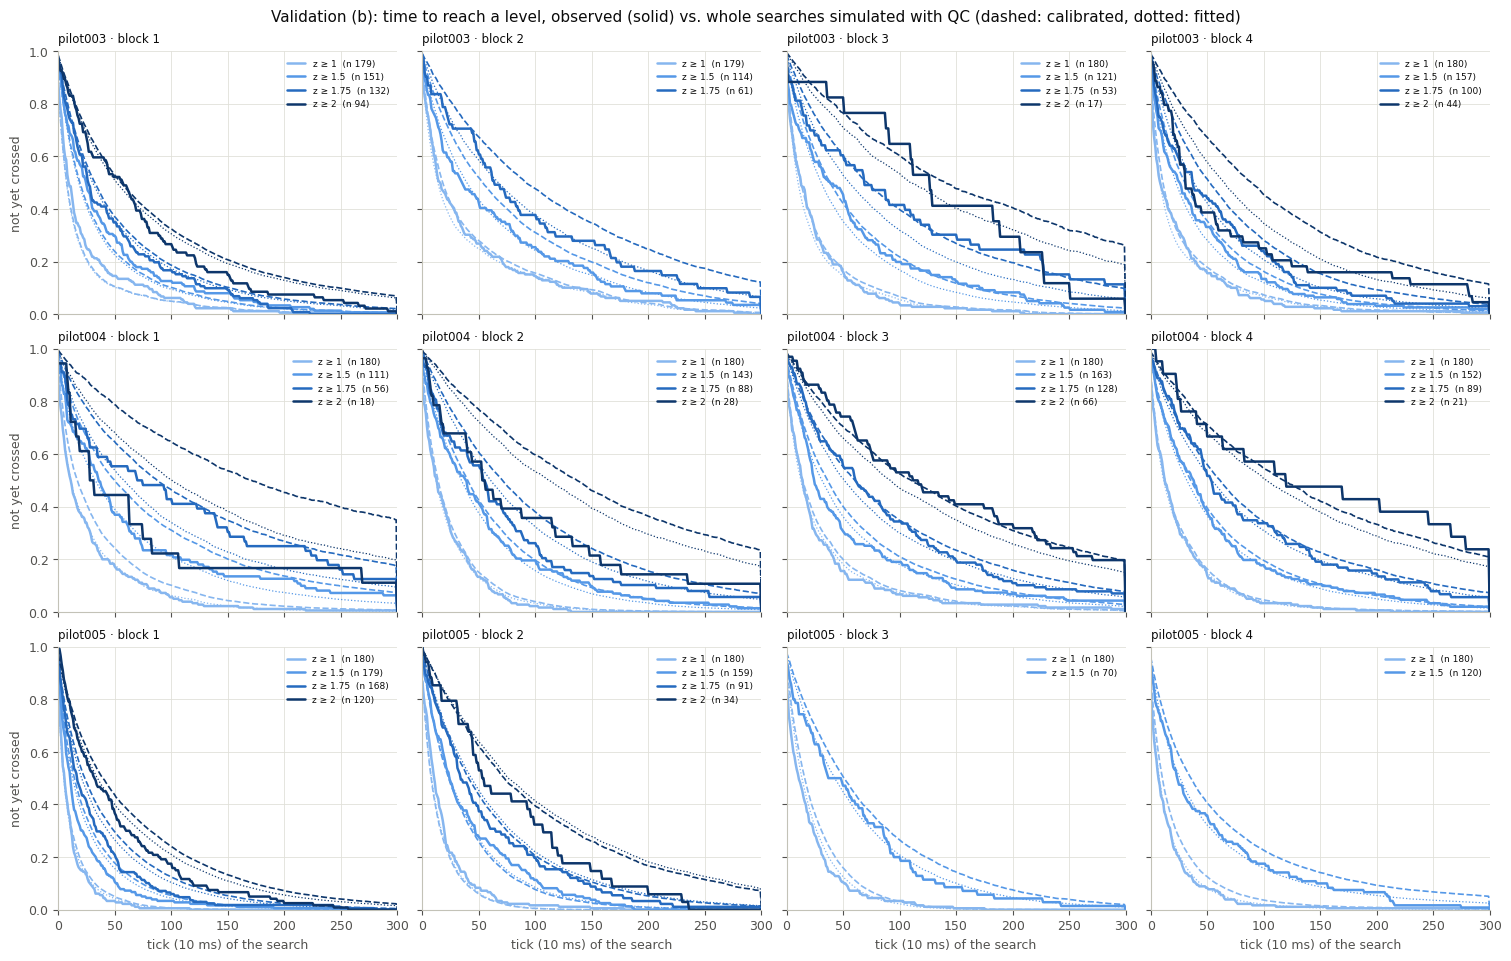

In [9]:
VERSIONS = ("fitted", "calibrated")


def thresholds_z(S, M, p_thr):
    """Per-trial threshold in z units for probability thresholds p_thr (scalar or per trial)."""
    return to_z(logit(np.broadcast_to(p_thr, (len(S["pr"]),))), S["pr"].g.values, M)


def observed_ZQ(S, M):
    """Observed traces padded with a never-crossing column at the deadline (for first_passage)."""
    Zy = session_z(S, M)
    N, K = Zy.shape
    Zo = np.concatenate([np.nan_to_num(Zy, nan=-99.0), np.full((N, 1), -99.0)], 1).astype(np.float32)
    Qo = np.concatenate([S["QC"], np.zeros((N, 1), bool)], 1)
    return Zo, Qo


def one_step(Y, obs, model, upto, beta):
    """One-tick-ahead predictive mean and SD of z at the observed ticks (Kalman filter, intercept fixed)."""
    N, K = Y.shape
    Tm, Q, P0, Z, s2m = model["Tm"], model["Q"], model["P0"], model["Z"], model["s2m"]
    a = np.zeros((N, 4)); P = np.broadcast_to(P0, (N, 4, 4)).copy(); Yc = np.nan_to_num(Y) - beta
    MU = np.full((N, K), np.nan); SD = np.full((N, K), np.nan)
    for k in range(K):
        act = k <= upto
        if not act.any():
            break
        if k > 0:
            a[act] = a[act] @ Tm.T
            P[act] = np.einsum("ij,njk,lk->nil", Tm, P[act], Tm) + Q
        m = obs[:, k] & act
        if m.any():
            Pm = P[m]; PZ = Pm @ Z; F = PZ @ Z + s2m; mu = a[m] @ Z
            MU[m, k] = mu + beta; SD[m, k] = np.sqrt(F)
            Kg = PZ / F[:, None]
            a[m] = a[m] + Kg * (Yc[m, k] - mu)[:, None]
            P[m] = Pm - np.einsum("ni,nj->nij", Kg, PZ)
    return MU, SD


def hazard_check(s):
    path = CACHE / f"sub-{s}_hazard_{MODEL_TAG}.pkl"
    if (cached := read_cache(path)) is not None:
        return cached
    check_budget(f"hazard check {s}")
    S, M, dyn = SESS[s], MARG[s], DYN[s]
    pr = S["pr"]; blk = pr.block.values
    Zy = session_z(S, M)
    c_on = thresholds_z(S, M, pr.threshold.values)
    out = {}
    for b in range(1, 5):
        m = blk == b
        obs = S["QC"][m] & np.isfinite(Zy[m])
        MU, SD = one_step(Zy[m], obs, dyn[b], S["obs_end"][m], dyn[b]["intercept"])
        ok = np.isfinite(MU)
        c = np.broadcast_to(c_on[m][:, None], MU.shape)[ok]
        mu, sd = MU[ok], SD[ok]
        n_obs = int((Zy[m][ok] >= c).sum())
        expected = lambda d: float(norm.sf((c + d - mu) / sd).sum())
        out[b] = dict(ticks=int(ok.sum()), observed=n_obs, expected=expected(0.0),
                      delta=float(optimize.brentq(lambda d: expected(d) - n_obs, -2, 3)))
    path.write_bytes(pickle.dumps(out))
    return out


HAZ = {s: hazard_check(s) for s in SUBJECTS}
DELTA = {s: {b: HAZ[s][b]["delta"] for b in range(1, 5)} for s in SUBJECTS}


def version_shift(s, blk, version):
    """Downward shift of the simulated predictor (z units) for each trial."""
    return np.zeros(len(blk)) if version == "fitted" else np.array([DELTA[s][b] for b in blk])


rows = [{"session": s, "block": b, "ticks": h["ticks"], "crossings observed": h["observed"],
         "expected by the fitted model": round(h["expected"], 1), "ratio": round(h["expected"] / h["observed"], 2),
         "calibration δ (z)": round(h["delta"], 3)} for s in SUBJECTS for b, h in HAZ[s].items()]
print("(a) one tick ahead: crossings of the threshold in force, over all logged ticks")
show(pd.DataFrame(rows).set_index(["session", "block"]))


def validate_session(s, M_sim=100, seed=11):
    path = CACHE / f"sub-{s}_validation_{cache_key(MODEL_TAG, M_sim, seed, PPC_LEVELS, CENSOR_DELTAS)}.pkl"
    if (cached := read_cache(path)) is not None:
        return cached
    check_budget(f"validating {s}")
    S, M, dyn, q = SESS[s], MARG[s], DYN[s], QCM[s]
    rng = np.random.default_rng(seed)
    pr = S["pr"]; N, K = len(pr), S["K"]
    blk = pr.block.values; forced = pr.is_forced.values
    c_on = thresholds_z(S, M, pr.threshold.values)
    Zo, Qo = observed_ZQ(S, M)
    icp = np.array([dyn[b]["intercept"] for b in blk])
    # (b, c) a whole new search for every trial: tick-0 QC state, and the onset-rate prior of that stratum
    pi0 = np.array([q[b]["pi0"] for b in blk])[:, None]
    ff = rng.random((N, M_sim)) < pi0
    ab = lambda key, j: np.array([q[b][key][j] for b in blk])[:, None]
    qinit = dict(rem=np.zeros(N, int), new=np.ones(N, bool), first_fail=ff,
                 lam_a=np.where(ff, ab("ab_fail", 0), ab("ab_pass", 0)), lam_b=np.where(ff, ab("ab_fail", 1), ab("ab_pass", 1)))
    P0 = np.stack([dyn[b]["P0"] for b in blk])
    Zs, Qs = simulate(np.zeros(N, int), np.zeros((N, 4)), P0, icp, blk, dyn, qinit, q, K + 1, M_sim, rng)
    cums = tick_counts(Qs)
    res = {"levels": [], "forced": [], "censor": []}
    for ver in VERSIONS:
        Zv = Zs - version_shift(s, blk, ver)[:, None, None].astype(np.float32)
        for c in PPC_LEVELS:
            for b in range(1, 5):
                el = (c_on >= c) & (blk == b)
                if el.sum() < 15:
                    continue
                ko, fo, _, _ = first_passage(Zo[el], Qo[el], np.full(el.sum(), c, np.float32), K)
                ks, fs, _, _ = first_passage(Zv[el], Qs[el], np.full((el.sum(), 1), c, np.float32), K,
                                             cums=(cums[0][el], cums[1][el]))
                res["levels"].append(dict(version=ver, level=c, block=b, n=int(el.sum()), obs_mean=ko.mean(),
                                          sim_mean=ks.mean(), obs_never=fo.mean(), sim_never=fs.mean(),
                                          obs_curve=np.array([(ko > t).mean() for t in range(K + 1)]),
                                          sim_curve=np.array([(ks > t).mean() for t in range(K + 1)])))
        ks, fs, qs_, _ = first_passage(Zv, Qs, c_on[:, None].astype(np.float32), K, cums=cums)
        for b in range(1, 5):
            m = blk == b
            res["forced"].append(dict(version=ver, block=b, obs=forced[m].mean(), sim=fs[m].mean(),
                                      sim_lo=np.quantile(fs[m].mean(0), 0.05), sim_hi=np.quantile(fs[m].mean(0), 0.95),
                                      obs_qc=pr.qc_failures.values[m].mean(), sim_qc=qs_[m].mean()))
        del Zv
    del Zs, Qs, cums
    # (d) censor-and-predict: stop each trace at its first crossing k1 of c_n - delta and predict when it crossed c_n
    Zy = session_z(S, M)
    k_obs = np.where(forced, K, S["stop"])
    for delta in CENSOR_DELTAS:
        k1, f1, _, _ = first_passage(Zo, Qo, (c_on - delta).astype(np.float32), K)
        use = ~f1 & (k1 < k_obs) & (k1 < K - 1)          # crossed the lower level strictly before the outcome
        if use.sum() < 20:
            continue
        a0 = np.zeros((N, 4)); Pn = np.zeros((N, 4, 4))
        for b in range(1, 5):
            m = blk == b
            kf = kalman(Zy[m], S["QC"][m] & np.isfinite(Zy[m]), dyn[b], np.where(use[m], k1[m], -1), keep=True,
                        beta=dyn[b]["intercept"])
            a0[m], Pn[m] = kf["a"], kf["P"]
        idx = np.flatnonzero(use)
        lam_a = np.zeros(len(idx)); lam_b = np.zeros(len(idx))
        for j, i in enumerate(idx):
            o, e = qc_history(S["QC"][i], int(k1[i]))
            ab_i = q[blk[i]]["ab_fail"] if not S["QC"][i, 0] else q[blk[i]]["ab_pass"]
            lam_a[j], lam_b[j] = ab_i[0] + o, ab_i[1] + e
        Zc, Qc = simulate(k1[idx] + 1, a0[idx], Pn[idx], icp[idx], blk[idx], dyn,
                          dict(rem=np.zeros(len(idx), int), lam_a=lam_a, lam_b=lam_b, new=np.zeros(len(idx), bool)),
                          q, K + 1, 200, rng)
        obs_part = np.arange(K + 1)[None, None, :] <= k1[idx][:, None, None]
        Qh = np.where(obs_part, Qo[idx][:, None, :], Qc)
        ko = k_obs[idx]
        for ver in VERSIONS:
            shift = version_shift(s, blk[idx], ver)[:, None, None].astype(np.float32)
            Zh = np.where(obs_part, Zo[idx][:, None, :], Zc - shift)
            kp, fp, _, _ = first_passage(Zh, Qh, c_on[idx][:, None].astype(np.float32), K)
            u = (kp < ko[:, None]).mean(1) + rng.random(len(idx)) * (kp == ko[:, None]).mean(1)
            res["censor"].append(dict(version=ver, delta=delta, n=len(idx), obs_rem=(ko - k1[idx]).mean(),
                                      sim_rem=(kp - k1[idx][:, None]).mean(), obs_forced=forced[idx].mean(),
                                      sim_forced=fp.mean(), pit=np.histogram(u, bins=5, range=(0, 1))[0] / len(idx)))
            del Zh
        del Zc, Qc, Qh
    path.write_bytes(pickle.dumps(res))
    return res


VAL = {s: validate_session(s) for s in SUBJECTS}
rows = []
for s in SUBJECTS:
    for c in PPC_LEVELS:
        r = {"session": s, "level z ≥": c}
        for ver in VERSIONS:
            lv = [x for x in VAL[s]["levels"] if x["level"] == c and x["version"] == ver]
            if not lv:
                continue
            n = np.array([x["n"] for x in lv])
            r["trials"] = int(n.sum())
            wavg = lambda key: float(np.average([x[key] for x in lv], weights=n))
            r["mean crossing tick, observed"] = wavg("obs_mean")
            r[f"mean crossing tick, {ver}"] = wavg("sim_mean")
            r["never crossed, observed (%)"] = 100 * wavg("obs_never")
            r[f"never crossed, {ver} (%)"] = 100 * wavg("sim_never")
        if "trials" in r:
            rows.append(r)
print("(b) crossing times of levels the data cover (blocks pooled, trials whose threshold was at least that level)")
show(pd.DataFrame(rows).set_index(["session", "level z ≥"]).round(1))
rows = []
for s in SUBJECTS:
    for b in range(1, 5):
        r = {"session": s, "block": b}
        for x in VAL[s]["forced"]:
            if x["block"] != b:
                continue
            r["forced, observed (%)"] = 100 * x["obs"]
            r[f"forced, {x['version']} (%)"] = f"{100 * x['sim']:.1f} ({100 * x['sim_lo']:.1f}-{100 * x['sim_hi']:.1f})"
            r["QC ticks/trial, observed"] = round(x["obs_qc"], 1)
            r["QC ticks/trial, model"] = round(x["sim_qc"], 1)
        rows.append(r)
print("(c) forced rate at the thresholds that ran (model: mean, 90 % of replicates)")
show(pd.DataFrame(rows).set_index(["session", "block"]).round(1))
rows = []
for s in SUBJECTS:
    for x in VAL[s]["censor"]:
        rows.append({"session": s, "Δ (z)": x["delta"], "version": x["version"], "trials": x["n"],
                     "remaining ticks, observed": x["obs_rem"], "remaining ticks, model": x["sim_rem"],
                     "forced, observed (%)": 100 * x["obs_forced"], "forced, model (%)": 100 * x["sim_forced"],
                     "PIT quintiles (%)": " / ".join(f"{100 * v:.0f}" for v in x["pit"])})
print("(d) censor-and-predict")
show(pd.DataFrame(rows).set_index(["session", "Δ (z)", "version"]).round(1))


def fig_validation():
    fig, axes = plt.subplots(len(SUBJECTS), 4, figsize=(15, 2.9 * len(SUBJECTS) + 0.8), squeeze=False, sharex=True,
                             sharey=True, layout="constrained")
    for i, s in enumerate(SUBJECTS):
        for b in range(1, 5):
            ax = axes[i, b - 1]
            for r in VAL[s]["levels"]:
                if r["block"] != b:
                    continue
                col = BLOCK_COLORS[list(PPC_LEVELS).index(r["level"])]
                if r["version"] == "calibrated":
                    ax.plot(r["obs_curve"], color=col, lw=1.8, label=f"z ≥ {r['level']:g}  (n {r['n']})")
                    ax.plot(r["sim_curve"], color=col, lw=1.2, ls="--")
                else:
                    ax.plot(r["sim_curve"], color=col, lw=0.9, ls=":")
            ax.set_xlim(0, 300); ax.set_ylim(0, 1)
            ax.set_title(f"{s} · block {b}", fontsize=8.5)
            if b == 1:
                ax.set_ylabel("not yet crossed")
            if i == len(SUBJECTS) - 1:
                ax.set_xlabel("tick (10 ms) of the search")
            ax.legend(fontsize=6.5, loc="upper right")
    fig.suptitle("Validation (b): time to reach a level, observed (solid) vs. whole searches simulated with QC "
                 "(dashed: calibrated, dotted: fitted)", fontsize=11)
    fig.savefig(FIG / "2_validation_crossing.png")
    plt.show() if IN_NOTEBOOK else plt.close(fig)


fig_validation()

## 5 · Every trial under any rule: observed trace + model continuation

For each trial and replicate, a full trace on ticks 0 … `ACTIVE_CAP`: the observed ticks up to the trigger (or the whole
window for a forced trial) and, after them, a draw from the model conditional on everything observed in that trial
(filtered state, the trial's own QC onset rate, an ongoing QC block at the deadline). Every rule is evaluated on the
same draws, in both versions (the calibrated one shifts the continuation down by the block's δ), so differences
between rules are not Monte-Carlo noise. A rule's outcome for a trial is **identified** (taken from the data) when it
fires or is forced within the observed part; the share that needs the continuation is reported with every result.

In [10]:
@functools.lru_cache(maxsize=None)
def continuation_start(s):
    """Filtered state after the last observed tick, QC state there, and the onset-rate posterior, per trial."""
    S, M, dyn, q = SESS[s], MARG[s], DYN[s], QCM[s]
    pr = S["pr"]; N, K = len(pr), S["K"]; blk = pr.block.values
    Zy = session_z(S, M)
    a0 = np.zeros((N, 4)); Pn = np.zeros((N, 4, 4))
    for b in range(1, 5):
        m = blk == b
        kf = kalman(Zy[m], S["QC"][m] & np.isfinite(Zy[m]), dyn[b], S["obs_end"][m], keep=True, beta=dyn[b]["intercept"])
        a0[m], Pn[m] = kf["a"], kf["P"]
    lam_a = np.zeros(N); lam_b = np.zeros(N); rem = np.zeros(N, int)
    rng = np.random.default_rng(SEED + 7)
    for i in range(N):
        qb = q[blk[i]]
        o, e = qc_history(S["QC"][i], int(S["obs_end"][i]))
        ab = qb["ab_fail"] if not S["QC"][i, 0] else qb["ab_pass"]
        lam_a[i], lam_b[i] = ab[0] + o, ab[1] + e
        if pr.is_forced[i] and not S["QC"][i, K - 1]:              # a QC block still running at the deadline
            row = S["QC"][i, :K]
            run_start = K - 1 - np.argmax(row[::-1]) if row.any() else -1     # last QC-passing tick
            elapsed = K - 1 - run_start                                       # blocked ticks so far
            pmf = qb["pmf0"] if run_start < 0 else qb["pmf1"]
            tail = pmf.copy(); tail[:elapsed] = 0                             # block length >= elapsed
            tail = tail / tail.sum() if tail.sum() > 0 else np.eye(len(pmf))[-1]
            rem[i] = max(0, rng.choice(len(tail), p=tail) - elapsed)
    return dict(a0=a0, P=Pn, lam_a=lam_a, lam_b=lam_b, rem=rem, intercept=np.array([dyn[b]["intercept"] for b in blk]))


def hybrid_chunk(s, cs, M, rng, K_tot):
    """Observed ticks + continuation for M replicates: Z, QC arrays (N, M, K_tot), fitted version."""
    S = SESS[s]; N, K = len(S["pr"]), S["K"]
    oe = S["obs_end"]
    Zc, Qc = simulate(oe + 1, cs["a0"], cs["P"], cs["intercept"], S["pr"].block.values, DYN[s],
                      dict(rem=cs["rem"], lam_a=cs["lam_a"], lam_b=cs["lam_b"], new=np.zeros(N, bool)), QCM[s], K_tot, M, rng)
    Zo, Qo = observed_ZQ(S, MARG[s])
    Zo = np.concatenate([Zo[:, :K], np.full((N, K_tot - K), -99.0, np.float32)], 1)
    Qo = np.concatenate([Qo[:, :K], np.zeros((N, K_tot - K), bool)], 1)
    obs = np.arange(K_tot)[None, None, :] <= oe[:, None, None]
    return np.where(obs, Zo[:, None, :], Zc), np.where(obs, Qo[:, None, :], Qc)

## 6 · The rules

All rules act on the same PRIME trials in session order and start from `THRESHOLD_INIT` where they adapt.

| family | threshold for trial n | what it steers |
|---|---|---|
| **active-wait target** (current rule) | θ ← θ + gain · (target − active wait) | mean active wait (QC-blocked time ignored) |
| **wall-wait target** (QC-aware) | θ ← θ + gain · (target − wall wait) | mean wall wait, i.e. the ITI (target 0.65 s ≈ the predetermined ITI) |
| **forced-rate controller** | θ ← θ + η · (target − forced) | the forced rate itself |
| **rolling quantile** | quantile *q* of the last 50 first-tick predictions | selectivity relative to the predictor's current output |
| **fixed relative** (oracle) | z = const relative to the fitted location/scale | as above, with the session's drift known in advance |
| **fixed absolute** | θ = const | — |

Also, the current rule and the fixed thresholds with an **active deadline** (QC-blocked ticks do not count against the
3.0 s, hard cap at `ACTIVE_CAP` ticks): what QC costs in forced pulses, and what removing that cost costs in ITI.

Per rule and trial the simulation keeps, summed over replicates: forced or not, wall and active wait, the delivered
state z (for a forced pulse, z at the forcing tick), whether it is in the top decile of the predictor's current output,
the threshold, and whether the outcome needed the continuation; plus per-replicate block means for the spread.

In [11]:
TOP_Z = float(norm.ppf(0.9))


def rolling_quantile_thresholds(S, q, window):
    """Threshold for trial n = quantile q of the first-tick predictions of the previous `window` PRIME trials
    (unselected, available online before any trigger). Until 10 are available: THRESHOLD_INIT."""
    N = len(S["pr"])
    has = S["QC"].any(axis=1)
    first = np.where(has, expit(S["Y"][np.arange(N), np.argmax(S["QC"], axis=1)]), np.nan)
    th = np.full(N, DC["THRESHOLD_INIT"])
    for n in range(N):
        prev = first[max(0, n - window):n]
        prev = prev[np.isfinite(prev)]
        if len(prev) >= 10:
            th[n] = np.quantile(prev, q)
    return th


def rule_list():
    R = []
    for T in WAIT_TARGETS:
        R.append(dict(name=f"active-wait target {T:.2f} s", family="active", kind="wait", wait="active", target=T))
    for T in WAIT_TARGETS:
        R.append(dict(name=f"wall-wait target {T:.2f} s", family="wall", kind="wait", wait="wall", target=T))
    for r in FORCED_TARGETS:
        R.append(dict(name=f"forced-rate target {100 * r:.0f} %", family="forced", kind="forced", target=r))
    for q in QUANTILES:
        R.append(dict(name=f"rolling quantile q={q:.2f}", family="quantile", kind="quantile", q=q))
    for z in REL_Z:
        R.append(dict(name=f"relative z={z:.3f}", family="relative", kind="relative", z=float(z)))
    for th in ABS_THRESHOLDS:
        R.append(dict(name=f"absolute θ={th:.3f}", family="absolute", kind="absolute", theta=float(th)))
    R.append(dict(name=f"active-wait target {DC['TARGET_WAIT']:.2f} s, active deadline", family="active_deadline",
                  kind="wait", wait="active", target=DC["TARGET_WAIT"], active_deadline=True))
    for th in ABS_THRESHOLDS:
        R.append(dict(name=f"absolute θ={th:.3f}, active deadline", family="absolute_ad", kind="absolute",
                      theta=float(th), active_deadline=True))
    for z in REL_Z:
        R.append(dict(name=f"relative z={z:.3f}, active deadline", family="relative_ad", kind="relative", z=float(z),
                      active_deadline=True))
    return R


RULES = rule_list()
RAN = f"active-wait target {DC['TARGET_WAIT']:.2f} s"                    # the rule as it ran
RAN_AD = f"active-wait target {DC['TARGET_WAIT']:.2f} s, active deadline"


def z_of_threshold(theta, gi, M):
    """z of probability thresholds theta (array) at intervention trial gi (scalar): to_z without the spline per call."""
    b = M["block_of_g"][gi]; mb = M["blocks"][b]
    loc = float(M["loc"](np.array([gi]))[0])
    return norm.ppf(mb["G"].cdf((logit(theta) - loc) / mb["scale"]))


def compact(S, k, f, qcb, zd, th):
    """Per-trial sums over replicates (chunks add up) and per-replicate block means (chunks concatenate)."""
    pr = S["pr"]; K = S["K"]; blk = pr.block.values
    obs_forced = pr.is_forced.values[:, None]
    k_obs = np.where(pr.is_forced.values, K, S["stop"])[:, None]
    wall = (k + 1) * TICK
    trig = ~f
    cont = (k > S["obs_end"][:, None]) & ~(obs_forced & f & (k == K))
    zf = zd.astype(np.float64)
    s32 = lambda x: np.asarray(x.sum(1), np.float32)
    return {"f": s32(f), "wall": s32(wall), "active": s32(np.maximum(0, wall - qcb * TICK)), "z": s32(zf),
            "top": s32(zf >= TOP_Z), "cont": s32(cont), "ztrig": s32(np.where(trig, zf, 0)), "ntrig": s32(trig),
            "theta": s32(np.broadcast_to(th, k.shape)), "same": s32((k == k_obs) & (f == obs_forced)),
            "over": s32(k > K), "kmax": np.asarray(k.max(1), np.float32),
            "blk_f": np.stack([f[blk == b].mean(0) for b in range(1, 5)]).astype(np.float32),
            "blk_z": np.stack([zf[blk == b].mean(0) for b in range(1, 5)]).astype(np.float32)}


def run_rules_chunk(s, Zh, Qh):
    """Evaluate every rule on one chunk of hybrid traces."""
    S, M = SESS[s], MARG[s]
    pr = S["pr"]; N, K = len(pr), S["K"]
    Mr = Zh.shape[1]
    g = pr.g.values
    obs_forced = pr.is_forced.values
    k_obs = np.where(obs_forced, K, S["stop"])
    cums = tick_counts(Qh)
    out = {}
    for R in RULES:
        ad = R.get("active_deadline", False)
        if R["kind"] in ("absolute", "relative", "quantile"):
            if R["kind"] == "absolute":
                th = np.full(N, R["theta"]); c = thresholds_z(S, M, th)
            elif R["kind"] == "relative":
                c = np.full(N, R["z"]); th = expit(from_z(c, g, M))
            else:
                th = rolling_quantile_thresholds(S, R["q"], QUANTILE_WINDOW); c = thresholds_z(S, M, th)
            k, f, qcb, zd = first_passage(Zh, Qh, c[:, None].astype(np.float32), K, ad, ACTIVE_CAP, cums)
            out[R["name"]] = compact(S, k, f, qcb, zd, th[:, None])
            continue
        # sequential rules: thresholds depend on earlier outcomes
        th = np.full(Mr, DC["THRESHOLD_INIT"], float)
        K_arr = np.zeros((N, Mr), np.int16); F_arr = np.zeros((N, Mr), bool); Q_arr = np.zeros((N, Mr), np.int16)
        Zd_arr = np.zeros((N, Mr), np.float32); TH_arr = np.zeros((N, Mr))
        for n in range(N):
            c = z_of_threshold(th, g[n], M).astype(np.float32)
            k, f, qcb, zd = first_passage(Zh[n], Qh[n], c, K, ad, ACTIVE_CAP, (cums[0][n], cums[1][n]))
            K_arr[n], F_arr[n], Q_arr[n], Zd_arr[n], TH_arr[n] = k, f, qcb, zd, th
            same = (k == k_obs[n]) & (f == obs_forced[n])
            wall = np.where(same, pr.search_time.values[n], (k + 1) * TICK + S["latency"])
            if R["kind"] == "wait":
                w = np.maximum(0.0, wall - qcb * TICK) if R["wait"] == "active" else wall
                th = np.clip(th + DC["THRESHOLD_GAIN"] * (R["target"] - w), DC["THRESHOLD_MIN"], DC["THRESHOLD_MAX"])
            else:
                th = np.clip(th + FORCED_ETA * (R["target"] - f), DC["THRESHOLD_MIN"], DC["THRESHOLD_MAX"])
        res = compact(S, K_arr, F_arr, Q_arr, Zd_arr, TH_arr)
        res["theta_reps"] = TH_arr.astype(np.float16)
        res["theta_err"] = float(np.abs(TH_arr - pr.threshold.values[:, None]).max())
        out[R["name"]] = res
    return out


def merge_parts(parts):
    out = {}
    for name in parts[0]:
        out[name] = {}
        for fld in parts[0][name]:
            vals = [p[name][fld] for p in parts]
            if fld in ("blk_f", "blk_z", "theta_reps"):
                out[name][fld] = np.concatenate(vals, axis=1)
            elif fld in ("theta_err", "kmax"):
                out[name][fld] = np.max(vals, axis=0)
            else:
                out[name][fld] = np.sum(vals, axis=0)
    return out


def simulate_session(s):
    key = cache_key(MODEL_TAG, N_REPLICATES, CHUNK, SEED, ACTIVE_CAP, FORCED_ETA, QUANTILE_WINDOW,
                    [r["name"] for r in RULES], "v4")
    path = CACHE / f"sub-{s}_rules_{key}.pkl"
    if (cached := read_cache(path)) is not None:
        return cached
    cs = continuation_start(s)
    S = SESS[s]; oe = S["obs_end"]
    shift = version_shift(s, S["pr"].block.values, "calibrated").astype(np.float32)
    after = np.arange(ACTIVE_CAP + 1)[None, :] > oe[:, None]
    parts = {v: [] for v in VERSIONS}
    part_paths = [CACHE / f"sub-{s}_rules_{key}_part{c0:04d}.pkl" for c0 in range(0, N_REPLICATES, CHUNK)]
    for c0, part in zip(range(0, N_REPLICATES, CHUNK), part_paths):
        res = read_cache(part)
        if res is None:
            check_budget(f"simulating {s} replicates {c0}+")
            rng = np.random.default_rng([SEED, c0, zlib.crc32(s.encode())])
            Zh, Qh = hybrid_chunk(s, cs, min(CHUNK, N_REPLICATES - c0), rng, ACTIVE_CAP + 1)
            res = {"fitted": run_rules_chunk(s, Zh, Qh)}
            Zh -= (after * shift[:, None])[:, None, :]
            res["calibrated"] = run_rules_chunk(s, Zh, Qh)
            del Zh, Qh
            part.write_bytes(pickle.dumps(res))
        for v in VERSIONS:
            parts[v].append(res[v])
    out = {v: merge_parts(parts[v]) for v in VERSIONS}
    path.write_bytes(pickle.dumps(out))
    for part in part_paths:                  # chunk files are no longer needed
        try:
            part.unlink()
        except OSError:
            pass
    return out


SIM = {}
for s in SUBJECTS:
    t0 = time.time()
    SIM[s] = simulate_session(s)
    print(f"{s}: {len(RULES)} rules x {N_REPLICATES} replicates x {len(VERSIONS)} versions ready ({time.time() - t0:.0f} s)")

rows = []
for s in SUBJECTS:
    o = SIM[s]["fitted"][RAN]; N = len(SESS[s]["pr"])
    rows.append({"session": s, "same delivery tick and forced status as online (%)": 100 * o["same"].sum() / (N * N_REPLICATES),
                 "max |θ − logged θ|": o["theta_err"],
                 "outcomes from the model (%)": 100 * o["cont"].sum() / (N * N_REPLICATES)})
print("Replay of the rule that ran (must be exact):")
show(pd.DataFrame(rows).set_index("session"))

pilot003: 91 rules x 200 replicates x 2 versions ready (0 s)
pilot004: 91 rules x 200 replicates x 2 versions ready (0 s)
pilot005: 91 rules x 200 replicates x 2 versions ready (0 s)
Replay of the rule that ran (must be exact):


,same delivery tick and forced status as online (%),max |θ − logged θ|,outcomes from the model (%)
session,,,
pilot003,100.0,2.220446e-16,0.0
pilot004,100.0,3.219647e-15,0.0
pilot005,100.0,0.000000e+00,0.0


## 7 · From delivered states to an expected N45

Single pulses carry the measured N45 (dipole amplitude `tep_amplitude_raw`, on a log scale and centred per session and
block) and the decider's label (`tep_amplitude`). Both are related to z of the prediction before the pulse: for a
predetermined pulse the prediction at the pulse, for a PRIME single z at the trigger (for a forced one, the filter's
prediction for the forcing tick). Triplets have no single-pulse N45 and enter only through their state.

- **Predetermined singles** are delivered at random times, so their slope is not shaped by any selection; but there are
  only ~70 per session and few at high z.
- **All singles** add the PRIME singles, which cover high z, but whose timing came with the trigger (the moment the
  prediction peaked, with QC passing).

Both slopes are carried into section 8. The pulse classes below show what the trigger achieved as it ran.

Slopes within session and block


n   slope  \
pulses                       outcome                               
predetermined singles        N45 amplitude, % per z  208    +0.2   
                             label, per z            208  +0.001   
all singles                  N45 amplitude, % per z  849    +7.2   
                             label, per z            849  +0.045   
PRIME singles only           N45 amplitude, % per z  641   +11.4   
                             label, per z            641  +0.074   
triggered PRIME singles only N45 amplitude, % per z  596   +23.0   
                             label, per z            596  +0.116   

                                                               95% CI  
pulses                       outcome                                   
predetermined singles        N45 amplitude, % per z      [-6.4, +7.0]  
                             label, per z            [-0.044, +0.040]  
all singles                  N45 amplitude, % per z     [+4.1, +10.4]  
                             label, per z            [+0.026, +0.064]  
PRIME singles only           N45 amplitude, % per z     [+6.2, +17.0]  
                             label, per z            [+0.037, +0.109]  
triggered PRIME singles only N45 amplitude, % per z    [+11.2, +36.2]  
                             label, per z            [+0.043, +0.190]

Pulse classes, all sessions (N45 relative to the mean of all singles of the same session and block)


,n,mean z,N45 vs block mean (%),95% CI,"predicted, predetermined slope (%)","predicted, all-singles slope (%)"
pulses,,,,,,
predetermined,208.0,0.04,-9.85,"[-15.3, -4.0]",NaN,NaN
PRIME forced,45.0,-0.24,-11.87,"[-22.8, +0.0]",NaN,NaN
PRIME triggered,596.0,1.97,4.68,"[+0.9, +8.7]",NaN,NaN
PRIME triggered − predetermined,NaN,1.93,16.12,"[+8.2, +25.3]",0.42,14.47
PRIME triggered − PRIME forced,NaN,2.21,18.78,"[+3.6, +36.8]",0.48,16.74
PRIME forced − predetermined,NaN,-0.28,-2.24,"[-15.1, +13.1]",-0.06,-1.94


Per session


Δz  N45 (%)          95% CI
session  difference                                                    
pilot003 PRIME triggered − predetermined  1.91    11.49   [-0.5, +25.2]
         PRIME forced − predetermined    -0.22     1.84  [-19.3, +28.7]
pilot004 PRIME triggered − predetermined  2.15    25.36  [+10.7, +41.9]
         PRIME forced − predetermined     0.01     1.83  [-21.2, +29.9]
pilot005 PRIME triggered − predetermined  1.75    11.94   [-1.2, +26.4]
         PRIME forced − predetermined    -0.86   -14.05   [-28.9, +4.3]

preceding ITI vs N45 (predetermined singles, n=207): +1.7 % per s (SE 5.8); the ITI differences between rules (≤ 0.4 s) do not matter through this path


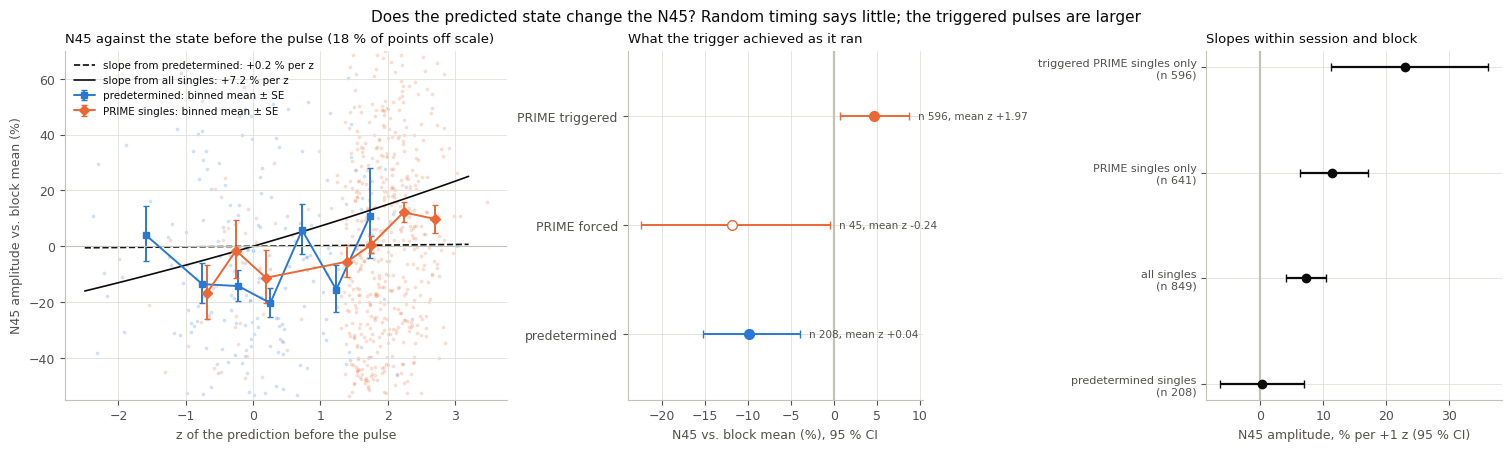

In [12]:
def single_pulse_table():
    rows = []
    for s in SUBJECTS:
        S, M = SESS[s], MARG[s]; iv = S["iv"]; pr = S["pr"]
        cs = continuation_start(s)
        # forced PRIME singles: predicted z at the forcing tick from the filtered state after tick K-1
        z_force = np.array([DYN[s][b]["Tm"] @ cs["a0"][i] for i, b in enumerate(pr.block.values)])
        z_force = z_force[:, 0] + z_force[:, 2] + z_force[:, 3] + cs["intercept"]
        zmap = {}
        for i, r in pr.iterrows():
            if r.condition == "prime_single_pulse":
                zmap[r.key] = z_force[i] if r.is_forced else to_z(S["Y"][i, S["stop"][i]], r.g, M)
        for _, r in iv[iv.condition.isin(["predetermined_single", "prime_single_pulse"])].iterrows():
            if r.condition == "predetermined_single":
                if not np.isfinite(r.prediction_probability):
                    continue
                z = float(to_z(logit(r.prediction_probability), r.g, M))
            else:
                z = float(zmap[r.key])
            rows.append(dict(session=s, block=r.block, condition=r.condition, forced=bool(r.is_forced), z=z,
                             label=r.tep_amplitude,
                             log_amp=np.log(r.tep_amplitude_raw) if r.tep_amplitude_raw > 0 else np.nan,
                             iti_prev=r.iti_prev, g=r.g))
    return pd.DataFrame(rows)


def fit_slope(df, y, rng, x="z", n_boot=N_BOOT):
    """Slope of y on x within (session, block), pooled; 95 % interval from resampling pulses within sessions."""
    d = df[np.isfinite(df[y].astype(float)) & np.isfinite(df[x].astype(float))]
    sb = pd.factorize(d.session.astype(str) + "_" + d.block.astype(str))[0]
    ses = pd.factorize(d.session)[0]
    yv, xv = d[y].values.astype(float), d[x].values.astype(float)
    nsb = sb.max() + 1

    def est(idx):
        g = sb[idx]; n = np.bincount(g, minlength=nsb).clip(1)
        yc = yv[idx] - (np.bincount(g, yv[idx], nsb) / n)[g]
        xc = xv[idx] - (np.bincount(g, xv[idx], nsb) / n)[g]
        return float((yc * xc).sum() / (xc * xc).sum())

    pools = [np.flatnonzero(ses == k) for k in range(ses.max() + 1)]
    boots = np.array([est(np.concatenate([rng.choice(p, len(p)) for p in pools])) for _ in range(n_boot)])
    return est(np.arange(len(d))), np.quantile(boots, [0.025, 0.975]), len(d)


def pct(v):
    """log ratio -> percent change"""
    return 100 * (np.exp(v) - 1)


SP = single_pulse_table()
SP["is_prime"] = (SP.condition == "prime_single_pulse").astype(float)
SP["triggered"] = ((SP.condition == "prime_single_pulse") & ~SP.forced).astype(float)
SP["prime_forced"] = ((SP.condition == "prime_single_pulse") & SP.forced).astype(float)
rng_b = np.random.default_rng(SEED + 99)
SLOPES = {}
rows = []
for name, sel in (("predetermined singles", SP.condition == "predetermined_single"), ("all singles", SP.z == SP.z),
                  ("PRIME singles only", SP.is_prime == 1), ("triggered PRIME singles only", SP.triggered == 1)):
    for y in ("log_amp", "label"):
        b, ci, n = fit_slope(SP[sel], y, rng_b)
        SLOPES[(name, y)] = dict(beta=b, ci=ci, n=n)
        amp = y == "log_amp"
        rows.append({"pulses": name, "outcome": "N45 amplitude, % per z" if amp else "label, per z", "n": n,
                     "slope": f"{pct(b):+.1f}" if amp else f"{b:+.3f}",
                     "95% CI": f"[{pct(ci[0]):+.1f}, {pct(ci[1]):+.1f}]" if amp else f"[{ci[0]:+.3f}, {ci[1]:+.3f}]"})
print("Slopes within session and block")
show(pd.DataFrame(rows).set_index(["pulses", "outcome"]))
BETA = {"pre": SLOPES[("predetermined singles", "log_amp")], "all": SLOPES[("all singles", "log_amp")]}


def class_table(d, rng, n_boot=N_BOOT):
    """Block-centred mean log N45 per pulse class, bootstrap CIs (pulses resampled within class)."""
    d = d[np.isfinite(d.log_amp)].copy()
    d["yc"] = d.log_amp - d.groupby(["session", "block"]).log_amp.transform("mean")
    cls = {"predetermined": d.condition == "predetermined_single", "PRIME forced": d.prime_forced == 1,
           "PRIME triggered": d.triggered == 1}
    boots, rows = {}, []
    for name, m in cls.items():
        v = d.yc[m].values
        boots[name] = np.array([v[rng.integers(0, len(v), len(v))].mean() for _ in range(n_boot)])
        rows.append({"pulses": name, "n": len(v), "mean z": d.z[m].mean(), "N45 vs block mean (%)": pct(v.mean()),
                     "95% CI": f"[{pct(np.quantile(boots[name], .025)):+.1f}, {pct(np.quantile(boots[name], .975)):+.1f}]"})
    for a, b in (("PRIME triggered", "predetermined"), ("PRIME triggered", "PRIME forced"), ("PRIME forced", "predetermined")):
        dv = boots[a] - boots[b]
        dz = d.z[cls[a]].mean() - d.z[cls[b]].mean()
        rows.append({"pulses": f"{a} − {b}", "mean z": dz, "N45 vs block mean (%)": pct(d.yc[cls[a]].mean() - d.yc[cls[b]].mean()),
                     "95% CI": f"[{pct(np.quantile(dv, .025)):+.1f}, {pct(np.quantile(dv, .975)):+.1f}]",
                     "predicted, predetermined slope (%)": pct(BETA["pre"]["beta"] * dz),
                     "predicted, all-singles slope (%)": pct(BETA["all"]["beta"] * dz)})
    return pd.DataFrame(rows).set_index("pulses"), d, cls, boots


CLASSES, SPC, CLS, _ = class_table(SP, rng_b)
print("Pulse classes, all sessions (N45 relative to the mean of all singles of the same session and block)")
show(CLASSES.round(2))
rows = []
for s in SUBJECTS:
    t = class_table(SP[SP.session == s], rng_b)[0]
    for r in ("PRIME triggered − predetermined", "PRIME forced − predetermined"):
        rows.append({"session": s, "difference": r, "Δz": t.loc[r, "mean z"], "N45 (%)": t.loc[r, "N45 vs block mean (%)"],
                     "95% CI": t.loc[r, "95% CI"]})
print("Per session")
show(pd.DataFrame(rows).set_index(["session", "difference"]).round(2))
d = SPC[(SPC.condition == "predetermined_single") & np.isfinite(SPC.iti_prev)]
lr = stats.linregress(d.iti_prev, d.yc)
print(f"preceding ITI vs N45 (predetermined singles, n={len(d)}): {100 * lr.slope:+.1f} % per s (SE {100 * lr.stderr:.1f}); "
      f"the ITI differences between rules (≤ 0.4 s) do not matter through this path")


def fig_amplitude():
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), layout="constrained", gridspec_kw=dict(width_ratios=[1.5, 1, 1]))
    ax = axes[0]
    d = SPC
    edges = np.array([-3.5, -1.0, -0.5, 0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 4.0])
    for name, cond, col, mk in (("predetermined", "predetermined_single", BLUE, "s"), ("PRIME singles", "prime_single_pulse", ORANGE, "D")):
        m = (d.condition == cond).values
        ax.scatter(d.z[m], pct(d.yc[m]), s=7, color=col, alpha=0.22, lw=0)
        idx = np.digitize(d.z[m], edges) - 1
        bx, by, be = [], [], []
        for j in range(len(edges) - 1):
            v = d.yc[m].values[idx == j]
            if len(v) >= 8:
                bx.append(d.z[m].values[idx == j].mean()); by.append(v.mean()); be.append(v.std(ddof=1) / np.sqrt(len(v)))
        bx, by, be = map(np.array, (bx, by, be))
        ax.errorbar(bx, pct(by), yerr=[pct(by) - pct(by - be), pct(by + be) - pct(by)], color=col, marker=mk, ms=5, lw=1.4,
                    capsize=2, label=f"{name}: binned mean ± SE")
    zz = np.linspace(-2.5, 3.2, 50)
    for key, ls, lab in (("pre", "--", "slope from predetermined"), ("all", "-", "slope from all singles")):
        ax.plot(zz, pct(BETA[key]["beta"] * zz), color=INK, ls=ls, lw=1.2, label=f"{lab}: {pct(BETA[key]['beta']):+.1f} % per z")
    ax.axhline(0, color=BASE_C, lw=0.8)
    ax.set_ylim(-55, 70)
    ax.set_xlabel("z of the prediction before the pulse"); ax.set_ylabel("N45 amplitude vs. block mean (%)")
    ax.set_title(f"N45 against the state before the pulse ({100 * np.mean((pct(d.yc) < -55) | (pct(d.yc) > 70)):.0f} % of points off scale)")
    ax.legend(fontsize=7.5, loc="upper left")
    ax = axes[1]
    names = ["predetermined", "PRIME forced", "PRIME triggered"]
    for j, (nm, col, face) in enumerate(zip(names, (BLUE, ORANGE, ORANGE), (BLUE, "white", ORANGE))):
        v = SPC.yc[CLS[nm]].values
        bs = np.array([v[rng_b.integers(0, len(v), len(v))].mean() for _ in range(N_BOOT)])
        m, l, h = pct(v.mean()), pct(np.quantile(bs, 0.025)), pct(np.quantile(bs, 0.975))
        ax.errorbar(m, j, xerr=[[m - l], [h - m]], fmt="o", color=col, mfc=face, ms=7, capsize=3, lw=1.4)
        ax.text(h + 1.0, j, f"n {len(v)}, mean z {SPC.z[CLS[nm]].mean():+.2f}", va="center", fontsize=7.5, color=INK_2)
    ax.axvline(0, color=BASE_C)
    ax.set_yticks(range(3), names); ax.set_ylim(-0.6, 2.6)
    ax.set_xlabel("N45 vs. block mean (%), 95 % CI")
    ax.set_title("What the trigger achieved as it ran")
    ax = axes[2]
    labs = ["predetermined singles", "all singles", "PRIME singles only", "triggered PRIME singles only"]
    for j, nm in enumerate(labs):
        r = SLOPES[(nm, "log_amp")]
        m, l, h = pct(r["beta"]), pct(r["ci"][0]), pct(r["ci"][1])
        ax.errorbar(m, j, xerr=[[m - l], [h - m]], fmt="o", color=INK, ms=6, capsize=3)
    ax.axvline(0, color=BASE_C)
    ax.set_yticks(range(len(labs)), [f"{nm}\n(n {SLOPES[(nm, 'log_amp')]['n']})" for nm in labs], fontsize=8)
    ax.set_xlabel("N45 amplitude, % per +1 z (95 % CI)")
    ax.set_title("Slopes within session and block")
    fig.suptitle("Does the predicted state change the N45? Random timing says little; the triggered pulses are larger", fontsize=11)
    fig.savefig(FIG / "3_amplitude_model.png")
    plt.show() if IN_NOTEBOOK else plt.close(fig)


fig_amplitude()

## 8 · Results

### 8.1 Summary per rule

Whole session (720 PRIME trials), means over replicates. **Forced** is given for the calibrated and the fitted model:
they agree where the outcome is identified and bracket the truth where it is extrapolated (section 4.5 d); all other
columns use the calibrated model. **Selectivity**: the mean delivered z (0 = random timing) and the share of pulses in
the top decile of the predictor's current output (10 % at random timing). **N45**: expected change of the single-pulse
N45 against random timing, with the slope from all singles and from predetermined pulses only (section 7).
*From the model*: share of outcomes that needed the continuation.

In [13]:
def rule_stats(s, name, blocks=(1, 2, 3, 4), version="calibrated"):
    S = SESS[s]; o = SIM[s][version][name]; blk = S["pr"].block.values
    m = np.isin(blk, blocks); n = m.sum() * N_REPLICATES
    w = np.array([np.sum(blk == b) for b in blocks], float)
    rep_f = (o["blk_f"][[b - 1 for b in blocks]] * w[:, None]).sum(0) / w.sum()
    zbar = float(o["z"][m].sum() / n)
    wall = float(o["wall"][m].sum() / n)
    return {"forced (%)": 100 * float(o["f"][m].sum() / n),
            "forced, 90 % of replicates": (100 * np.quantile(rep_f, 0.05), 100 * np.quantile(rep_f, 0.95)),
            "wall wait (s)": wall, "active wait (s)": float(o["active"][m].sum() / n),
            "PRIME ITI (s)": S["t_search_start"] + wall + S["latency"], "mean θ": float(o["theta"][m].sum() / n),
            "mean z": zbar, "mean z, triggered": float(o["ztrig"][m].sum() / max(o["ntrig"][m].sum(), 1)),
            "top decile (%)": 100 * float(o["top"][m].sum() / n),
            "N45, all-singles slope (%)": float(pct(BETA["all"]["beta"] * zbar)),
            "N45, predetermined slope (%)": float(pct(BETA["pre"]["beta"] * zbar)),
            "from the model (%)": 100 * float(o["cont"][m].sum() / n),
            "searches past 3.0 s (%)": 100 * float(o["over"][m].sum() / n),
            "longest search (s)": float((o["kmax"][m].max() + 1) * TICK)}


KEY_RULES = ([RAN] + [f"active-wait target {T:.2f} s" for T in WAIT_TARGETS if f"active-wait target {T:.2f} s" != RAN] + [RAN_AD]
             + [f"wall-wait target {T:.2f} s" for T in WAIT_TARGETS] + [f"forced-rate target {100 * r:.0f} %" for r in FORCED_TARGETS]
             + [f"rolling quantile q={q:.2f}" for q in QUANTILES])
rows = []
for s in SUBJECTS:
    pr = SESS[s]["pr"]
    print(f"{s} as ran: forced {100 * pr.is_forced.mean():.1f} %, PRIME ITI {pr.iti_prev.mean():.2f} s, "
          f"predetermined ITI {SESS[s]['pdm'].iti_prev.mean():.2f} s")
    for nm in KEY_RULES:
        c, f = rule_stats(s, nm), rule_stats(s, nm, version="fitted")
        rows.append({"session": s, "rule": nm + ("  (as ran)" if nm == RAN else ""), "forced (%)": c["forced (%)"],
                     "forced, fitted (%)": f["forced (%)"], "PRIME ITI (s)": c["PRIME ITI (s)"], "mean θ": c["mean θ"],
                     "mean z": c["mean z"], "top decile (%)": c["top decile (%)"],
                     "N45 (%), all-singles slope": c["N45, all-singles slope (%)"],
                     "N45 (%), predetermined slope": c["N45, predetermined slope (%)"],
                     "from the model (%)": c["from the model (%)"]})
SUMMARY = pd.DataFrame(rows).set_index(["session", "rule"])
show(SUMMARY.round(2))
SUMMARY.to_csv(OUT / "rule_summary.csv")

pilot003 as ran: forced 6.9 %, PRIME ITI 3.38 s, predetermined ITI 3.19 s
pilot004 as ran: forced 10.8 %, PRIME ITI 3.51 s, predetermined ITI 3.19 s
pilot005 as ran: forced 3.2 %, PRIME ITI 3.22 s, predetermined ITI 3.15 s


forced (%)  \
session  rule                                                     
pilot003 active-wait target 0.65 s  (as ran)               6.94   
         active-wait target 0.40 s                         1.80   
         active-wait target 0.90 s                        13.58   
         active-wait target 0.65 s, active deadline        4.55   
         wall-wait target 0.40 s                           0.42   
         wall-wait target 0.65 s                           2.95   
         wall-wait target 0.90 s                           7.51   
         forced-rate target 2 %                            2.79   
         forced-rate target 5 %                            5.73   
         forced-rate target 10 %                          10.68   
         rolling quantile q=0.70                           0.14   
         rolling quantile q=0.80                           0.14   
         rolling quantile q=0.85                           0.28   
         rolling quantile q=0.90                           1.62   
         rolling quantile q=0.95                           6.34   
pilot004 active-wait target 0.65 s  (as ran)              10.83   
         active-wait target 0.40 s                         3.93   
         active-wait target 0.90 s                        20.12   
         active-wait target 0.65 s, active deadline        4.34   
         wall-wait target 0.40 s                           1.83   
         wall-wait target 0.65 s                           4.22   
         wall-wait target 0.90 s                           8.70   
         forced-rate target 2 %                            3.47   
         forced-rate target 5 %                            6.02   
         forced-rate target 10 %                          10.83   
         rolling quantile q=0.70                           0.42   
         rolling quantile q=0.80                           1.05   
         rolling quantile q=0.85                           1.56   
         rolling quantile q=0.90                           3.50   
         rolling quantile q=0.95                          11.62   
pilot005 active-wait target 0.65 s  (as ran)               3.19   
         active-wait target 0.40 s                         0.60   
         active-wait target 0.90 s                         8.41   
         active-wait target 0.65 s, active deadline        2.69   
         wall-wait target 0.40 s                           0.29   
         wall-wait target 0.65 s                           2.73   
         wall-wait target 0.90 s                           6.79   
         forced-rate target 2 %                            2.91   
         forced-rate target 5 %                            5.83   
         forced-rate target 10 %                          10.68   
         rolling quantile q=0.70                           0.14   
         rolling quantile q=0.80                           0.14   
         rolling quantile q=0.85                           0.14   
         rolling quantile q=0.90                           0.15   
         rolling quantile q=0.95                           5.60   

                                                     forced, fitted (%)  \
session  rule                                                             
pilot003 active-wait target 0.65 s  (as ran)                       6.94   
         active-wait target 0.40 s                                 1.83   
         active-wait target 0.90 s                                12.97   
         active-wait target 0.65 s, active deadline                4.31   
         wall-wait target 0.40 s                                   0.43   
         wall-wait target 0.65 s                                   2.92   
         wall-wait target 0.90 s                                   7.28   
         forced-rate target 2 %                                    2.79   
         forced-rate target 5 %                                    5.71   
         forced-rate target 10 %                                  10.65   
   

### 8.2 Fixed thresholds: forced pulses, selectivity and N45 as a function of the threshold

(a) Absolute probability thresholds, per block: because the predictor drifts down, the same θ forces more pulses from
block to block (★: each block as it ran). (b–d) Thresholds relative to the predictor's current output (z, with its
percentile), blocks pooled: the forced rate with the wall deadline that ran (solid) and with QC-blocked time not
counted (dashed; the gap is what QC adds), the share of pulses in the top decile, and the expected N45. Lines: the
calibrated model; bands reach to the fitted model; pale background: more than half of the outcomes from the model.

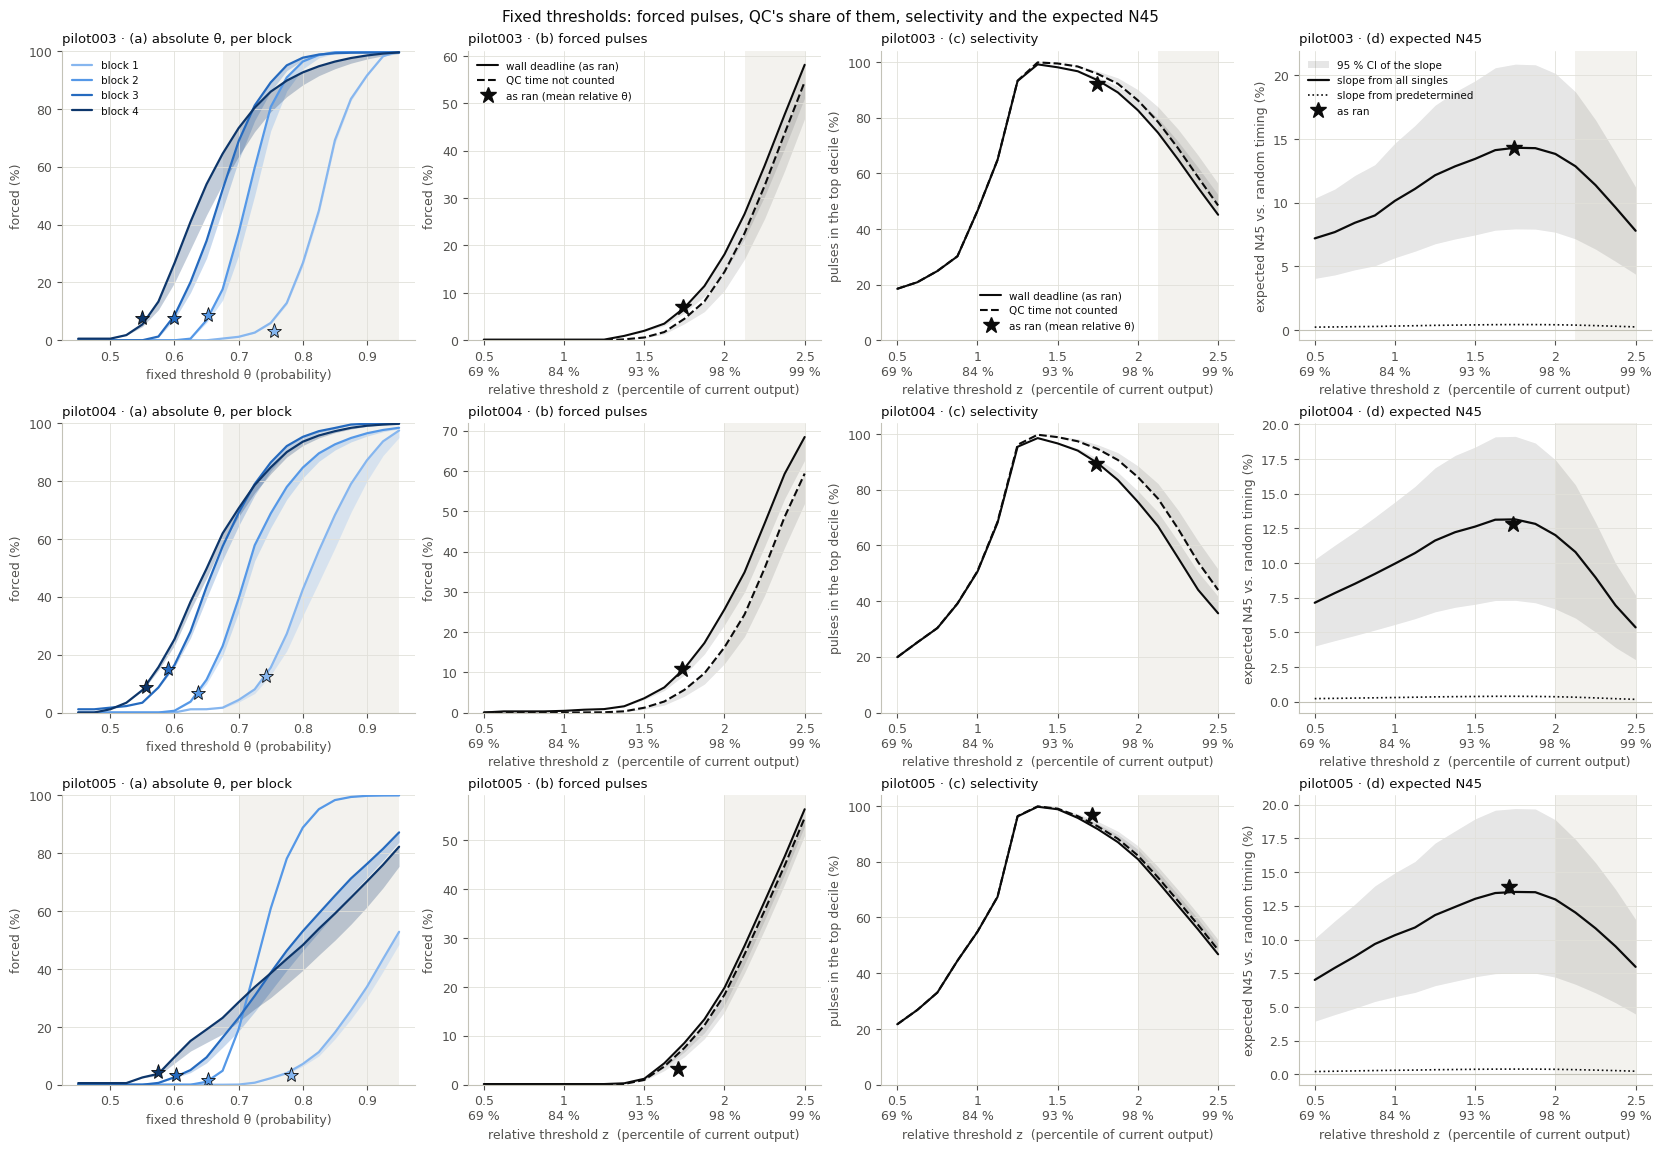

In [14]:
def rel_ticks(ax):
    ticks = [0.5, 1.0, 1.5, 2.0, 2.5]
    ax.set_xticks(ticks, [f"{t:g}\n{100 * norm.cdf(t):.0f} %" for t in ticks])
    ax.set_xlabel("relative threshold z  (percentile of current output)")


def shade_extrapolated(ax, x, names, s):
    cont = np.array([rule_stats(s, nm)["from the model (%)"] for nm in names])
    if (cont > 50).any():
        ax.axvspan(x[np.argmax(cont > 50)], x.max(), color=WASH, zorder=0, lw=0)


def ran_relative(s):
    S = SESS[s]
    return float(thresholds_z(S, MARG[s], S["pr"].threshold.values).mean())


def fig_fixed():
    absn = [f"absolute θ={t:.3f}" for t in ABS_THRESHOLDS]
    reln = [f"relative z={z:.3f}" for z in REL_Z]
    reln_ad = [f"relative z={z:.3f}, active deadline" for z in REL_Z]
    fig, axes = plt.subplots(len(SUBJECTS), 4, figsize=(16.5, 3.5 * len(SUBJECTS) + 0.9), squeeze=False, layout="constrained")
    for i, s in enumerate(SUBJECTS):
        pr = SESS[s]["pr"]
        ran = rule_stats(s, RAN); x_ran = ran_relative(s)
        ax = axes[i, 0]
        shade_extrapolated(ax, ABS_THRESHOLDS, absn, s)
        for b in range(1, 5):
            cal = [rule_stats(s, nm, (b,))["forced (%)"] for nm in absn]
            fit = [rule_stats(s, nm, (b,), "fitted")["forced (%)"] for nm in absn]
            ax.fill_between(ABS_THRESHOLDS, fit, cal, color=BLOCK_COLORS[b - 1], alpha=0.25, lw=0)
            ax.plot(ABS_THRESHOLDS, cal, color=BLOCK_COLORS[b - 1], lw=1.6, label=f"block {b}")
            mb = pr.block.values == b
            ax.plot(pr.threshold.values[mb].mean(), 100 * pr.is_forced.values[mb].mean(), marker="*", ms=11,
                    color=BLOCK_COLORS[b - 1], mec=INK, mew=0.6, ls="none")
        ax.set_ylim(0, 100); ax.set_xlabel("fixed threshold θ (probability)"); ax.set_ylabel("forced (%)")
        ax.set_title(f"{s} · (a) absolute θ, per block")
        if i == 0:
            ax.legend(fontsize=7.5, loc="upper left")
        for j, (field, ylab, title) in enumerate((("forced (%)", "forced (%)", "(b) forced pulses"),
                                                   ("top decile (%)", "pulses in the top decile (%)", "(c) selectivity"))):
            ax = axes[i, 1 + j]
            shade_extrapolated(ax, REL_Z, reln, s)
            for names, ls, lab in ((reln, "-", "wall deadline (as ran)"), (reln_ad, "--", "QC time not counted")):
                cal = [rule_stats(s, nm)[field] for nm in names]
                fit = [rule_stats(s, nm, version="fitted")[field] for nm in names]
                ax.fill_between(REL_Z, fit, cal, color=INK, alpha=0.10, lw=0)
                ax.plot(REL_Z, cal, color=INK, ls=ls, lw=1.5, label=lab)
            ax.plot(x_ran, ran[field], marker="*", ms=12, color=INK, ls="none", label="as ran (mean relative θ)")
            rel_ticks(ax); ax.set_ylabel(ylab); ax.set_ylim(0, None)
            ax.set_title(f"{s} · {title}")
            if i == 0:
                ax.legend(fontsize=7.5, loc="upper left" if j == 0 else "lower center")

        ax = axes[i, 3]
        shade_extrapolated(ax, REL_Z, reln, s)
        zbar = np.array([rule_stats(s, nm)["mean z"] for nm in reln])
        lo, hi = BETA["all"]["ci"]
        ax.fill_between(REL_Z, pct(lo * zbar), pct(hi * zbar), color=INK, alpha=0.10, lw=0, label="95 % CI of the slope")
        ax.plot(REL_Z, pct(BETA["all"]["beta"] * zbar), color=INK, lw=1.6, label="slope from all singles")
        ax.plot(REL_Z, pct(BETA["pre"]["beta"] * zbar), color=INK, lw=1.2, ls=":", label="slope from predetermined")
        ax.plot(x_ran, ran["N45, all-singles slope (%)"], marker="*", ms=12, color=INK, ls="none", label="as ran")
        ax.axhline(0, color=BASE_C, lw=0.8)
        rel_ticks(ax); ax.set_ylabel("expected N45 vs. random timing (%)")
        ax.set_title(f"{s} · (d) expected N45")
        if i == 0:
            ax.legend(fontsize=7.5, loc="upper left")
    fig.suptitle("Fixed thresholds: forced pulses, QC's share of them, selectivity and the expected N45", fontsize=11)
    fig.savefig(FIG / "4_fixed_thresholds.png")
    plt.show() if IN_NOTEBOOK else plt.close(fig)


fig_fixed()

### 8.3 Adaptive rules: the trade-off, and how the threshold moves

(a) Every rule as one point: forced pulses against the expected N45 (slope from all singles; with the predetermined
slope every rule sits at ≈ 0 %). Up and to the left is better. Grey: fixed thresholds relative to the predictor's
current output, which would need the drift known in advance; a reference, not a bound (the adaptive rules also follow
block-to-block differences in QC and dynamics). Horizontal bars span the fitted to the calibrated model. Rolling
quantiles below 0.90 are far less selective (table 8.1) and left out. (b) The threshold over the session (median over
replicates, band 5–95 %). (c) Forced pulses per block.

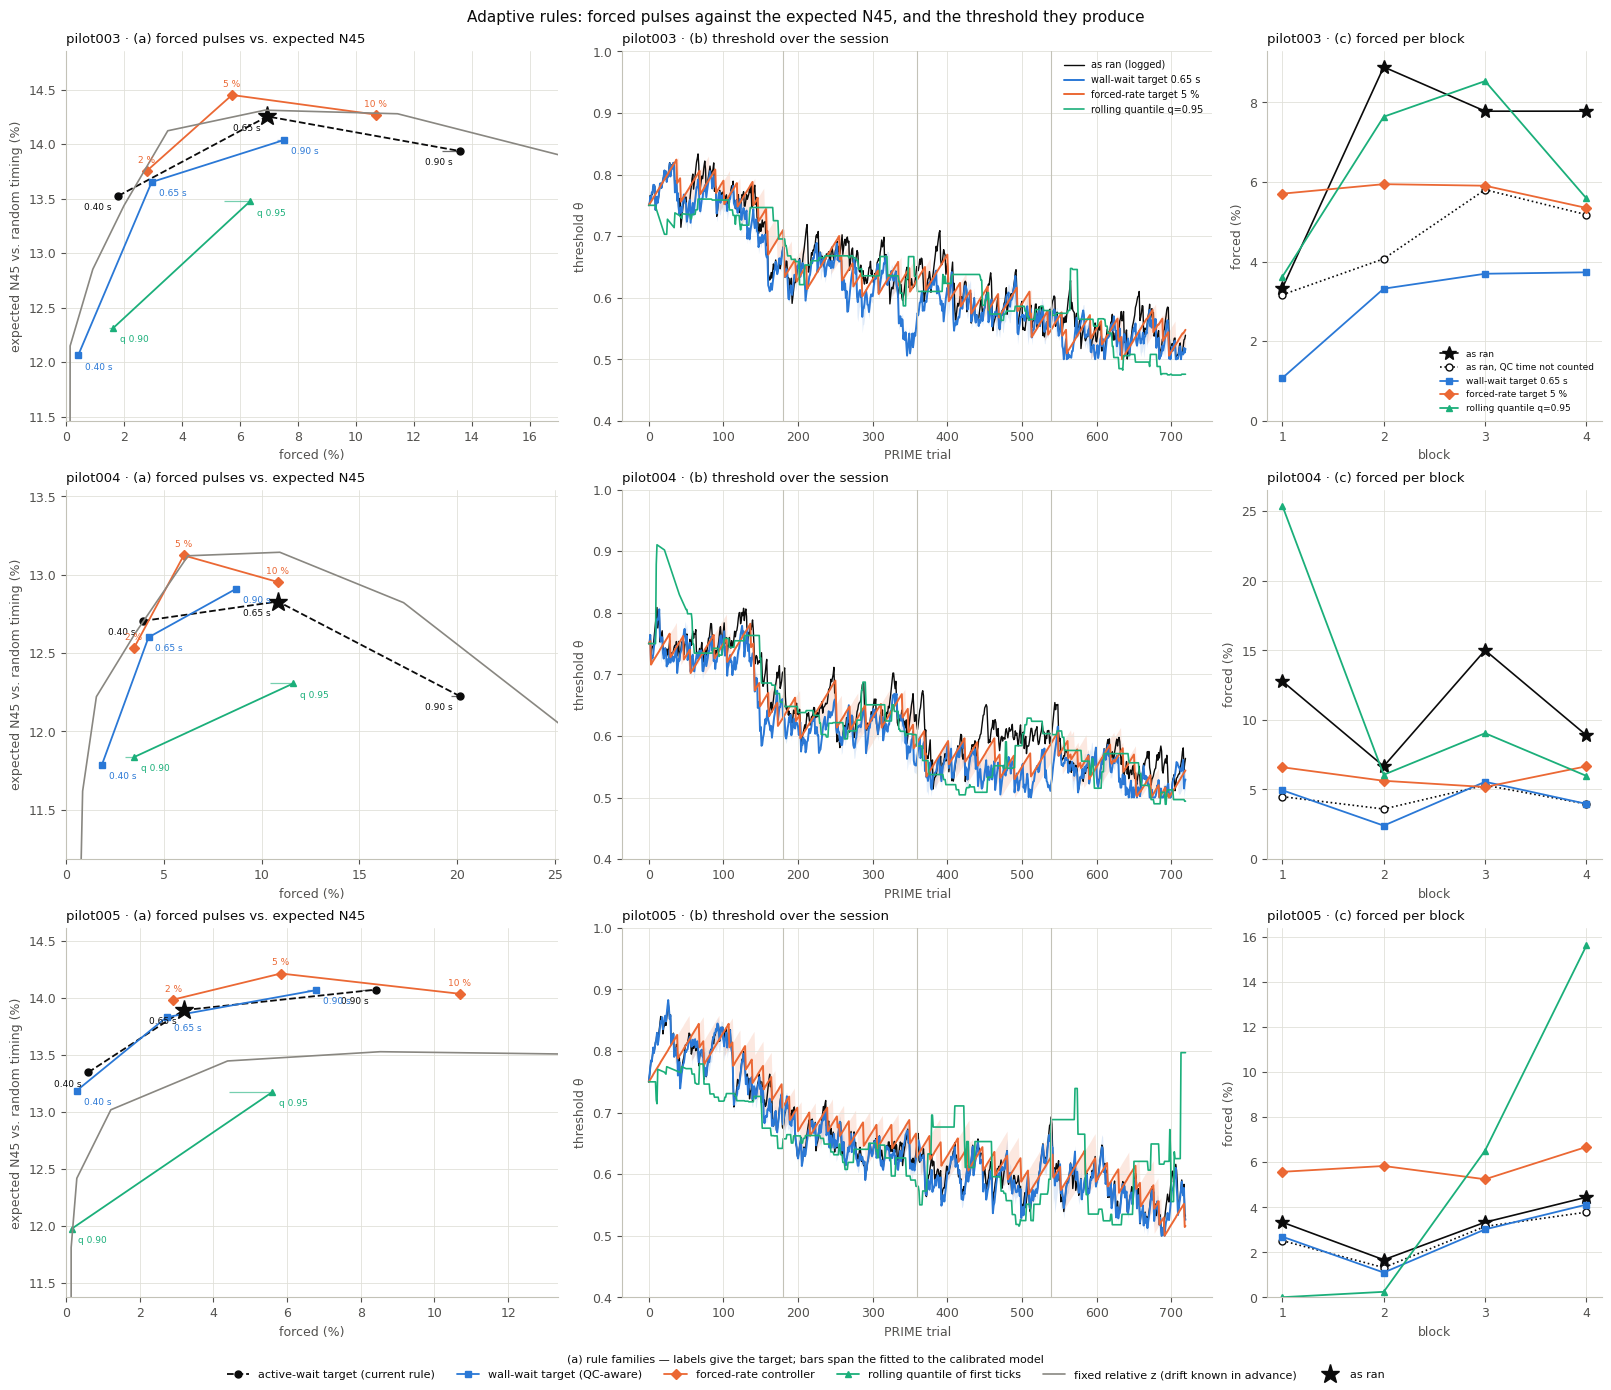

In [15]:
SHOW = [("wall", f"wall-wait target {DC['TARGET_WAIT']:.2f} s"), ("forced", "forced-rate target 5 %"),
        ("quantile", "rolling quantile q=0.95")]
FIG_QUANTILES = [q for q in QUANTILES if q >= 0.9]          # lower quantiles are far less selective (see 8.1)


def fig_tradeoff():
    fams = [("active", [f"active-wait target {T:.2f} s" for T in WAIT_TARGETS], [f"{T:.2f} s" for T in WAIT_TARGETS], (-5, -10), "right"),
            ("wall", [f"wall-wait target {T:.2f} s" for T in WAIT_TARGETS], [f"{T:.2f} s" for T in WAIT_TARGETS], (5, -10), "left"),
            ("forced", [f"forced-rate target {100 * r:.0f} %" for r in FORCED_TARGETS], [f"{100 * r:.0f} %" for r in FORCED_TARGETS], (0, 6), "center"),
            ("quantile", [f"rolling quantile q={q:.2f}" for q in FIG_QUANTILES], [f"q {q:.2f}" for q in FIG_QUANTILES], (5, -10), "left")]
    fig = plt.figure(figsize=(16, 4.2 * len(SUBJECTS) + 1.2), layout="constrained")
    gs = fig.add_gridspec(len(SUBJECTS), 3, width_ratios=[1.25, 1.5, 0.85])
    handles = []
    for i, s in enumerate(SUBJECTS):
        pr = SESS[s]["pr"]; blk = pr.block.values
        ax = fig.add_subplot(gs[i, 0])
        xs, ys = [], []
        for fam, names, labs, off, ha in fams:
            st = FAMILY_STYLE[fam]
            cal = [rule_stats(s, nm) for nm in names]
            fit = [rule_stats(s, nm, version="fitted") for nm in names]
            x = np.array([c["forced (%)"] for c in cal]); y = np.array([c["N45, all-singles slope (%)"] for c in cal])
            xf = np.array([f["forced (%)"] for f in fit])
            h, = ax.plot(x, y, color=st["color"], marker=st["marker"], ms=5, ls=st["ls"], lw=1.3, label=st["label"])
            ax.hlines(y, np.minimum(x, xf), np.maximum(x, xf), color=st["color"], lw=0.9, alpha=0.6)
            for xx, yy, lab in zip(x, y, labs):
                ax.annotate(lab, (xx, yy), fontsize=6.5, color=st["color"], xytext=off, textcoords="offset points", ha=ha)
            xs += list(x) + list(xf); ys += list(y)
            if i == 0:
                handles.append(h)
        ran = rule_stats(s, RAN)
        h, = ax.plot(ran["forced (%)"], ran["N45, all-singles slope (%)"], marker="*", ms=14, color=INK, ls="none", label="as ran")
        x_hi = max(10.0, 1.25 * max(xs))
        rel = [rule_stats(s, f"relative z={z:.3f}") for z in REL_Z]
        rx = np.array([r["forced (%)"] for r in rel]); ry = np.array([r["N45, all-singles slope (%)"] for r in rel])
        hr, = ax.plot(rx, ry, color=INK_MUTED, lw=1.2, label=FAMILY_STYLE["relative"]["label"])
        if i == 0:
            handles += [hr, h]
        vis = rx <= x_hi
        ax.set_xlim(0, x_hi)
        ax.set_ylim(min(ys) - 0.6, max(max(ys), ry[vis].max() if vis.any() else max(ys)) + 0.4)

        ax.set_xlabel("forced (%)"); ax.set_ylabel("expected N45 vs. random timing (%)")
        ax.set_title(f"{s} · (a) forced pulses vs. expected N45")
        ax = fig.add_subplot(gs[i, 1])
        n = np.arange(len(pr))
        ax.plot(n, pr.threshold.values, color=INK, lw=1.0, label="as ran (logged)")
        for fam, nm in SHOW:
            o = SIM[s]["calibrated"][nm]; st = FAMILY_STYLE[fam]
            if "theta_reps" in o:
                th = o["theta_reps"].astype(float)
                ax.fill_between(n, np.quantile(th, 0.05, 1), np.quantile(th, 0.95, 1), color=st["color"], alpha=0.15, lw=0)
                ax.plot(n, np.median(th, 1), color=st["color"], lw=1.4, label=nm)
            else:
                ax.plot(n, o["theta"] / N_REPLICATES, color=st["color"], lw=1.2, label=nm)
        for b in range(2, 5):
            ax.axvline(np.argmax(blk == b) - 0.5, color=BASE_C, lw=0.8)
        ax.set_ylim(0.4, 1.0); ax.set_xlabel("PRIME trial"); ax.set_ylabel("threshold θ")
        ax.set_title(f"{s} · (b) threshold over the session")
        if i == 0:
            ax.legend(fontsize=7, loc="upper right")
        ax = fig.add_subplot(gs[i, 2])
        ax.plot(range(1, 5), [100 * pr.is_forced.values[blk == b].mean() for b in range(1, 5)], color=INK, marker="*", ms=10,
                lw=1.2, label="as ran")
        ax.plot(range(1, 5), 100 * SIM[s]["calibrated"][RAN_AD]["blk_f"].mean(1), color=INK, marker="o", mfc="white", ms=5,
                ls=":", lw=1.2, label="as ran, QC time not counted")
        for fam, nm in SHOW:
            st = FAMILY_STYLE[fam]
            ax.plot(range(1, 5), 100 * SIM[s]["calibrated"][nm]["blk_f"].mean(1), color=st["color"], marker=st["marker"], ms=5,
                    lw=1.3, label=nm)
        ax.set_xticks(range(1, 5)); ax.set_xlabel("block"); ax.set_ylabel("forced (%)"); ax.set_ylim(0, None)
        ax.set_title(f"{s} · (c) forced per block")
        if i == 0:
            ax.legend(fontsize=6.5, loc="best")
    fig.legend(handles=handles, loc="outside lower center", ncol=len(handles), fontsize=8,
               title="(a) rule families — labels give the target; bars span the fitted to the calibrated model", title_fontsize=8)
    fig.suptitle("Adaptive rules: forced pulses against the expected N45, and the threshold they produce", fontsize=11)
    fig.savefig(FIG / "5_adaptive_rules.png")
    plt.show() if IN_NOTEBOOK else plt.close(fig)


fig_tradeoff()

### 8.4 Where the forced pulses come from

For the rule as ran: forced pulses split by how much of their 3.0 s QC blocked, and what not counting QC-blocked time
against the deadline would have changed (forced rate, ITI, and how long the longest search would get).

In [16]:
rows = []
for s in SUBJECTS:
    S = SESS[s]; pr = S["pr"]
    f = pr.is_forced.values; qct = pr.qc_failures.values * TICK
    cur, ad, adf = rule_stats(s, RAN), rule_stats(s, RAN_AD), rule_stats(s, RAN_AD, version="fitted")
    rows.append({"session": s, "forced as ran": int(f.sum()), "  of which ≥ 0.5 s QC-blocked": int((f & (qct >= 0.5)).sum()),
                 "  of which ≥ 1.0 s QC-blocked": int((f & (qct >= 1.0)).sum()),
                 "forced as ran (%)": 100 * f.mean(),
                 "forced, QC time not counted (%)": f"{ad['forced (%)']:.1f} (fitted {adf['forced (%)']:.1f})",
                 "PRIME ITI as ran (s)": cur["PRIME ITI (s)"], "PRIME ITI, QC time not counted (s)": ad["PRIME ITI (s)"],
                 "searches past 3.0 s, QC time not counted (%)": ad["searches past 3.0 s (%)"],
                 "longest search, QC time not counted (s)": ad["longest search (s)"]})
show(pd.DataFrame(rows).set_index("session").round(2).T)

session,pilot003,pilot004,pilot005
forced as ran,50,78,23
of which ≥ 0.5 s QC-blocked,18,59,3
of which ≥ 1.0 s QC-blocked,11,40,1
forced as ran (%),6.94,10.83,3.19
"forced, QC time not counted (%)",4.6 (fitted 4.3),4.3 (fitted 3.9),2.7 (fitted 2.6)
PRIME ITI as ran (s),3.38,3.51,3.22
"PRIME ITI, QC time not counted (s)",3.39,3.53,3.22
"searches past 3.0 s, QC time not counted (%)",3.75,8.4,2.08
"longest search, QC time not counted (s)",6.01,6.01,6.01


### 8.5 What this says (pilot003–005)

1. **QC causes a large share of the forced pulses under the current rule.** A search starts QC-blocked in 8–28 % of
   trials, and in forced trials QC took 0.25–1.14 s of the 3.0 s. Not counting QC time against the deadline would cut
   forced pulses from 6.9 / 10.8 / 3.2 % to about 4.6 / 4.3 / 2.7 %: QC accounts for roughly a third, three fifths and a
   sixth of them. Because the update ignores QC time, the PRIME ITI also ends up longer than the predetermined ITI
   (3.38 / 3.51 / 3.22 s against 3.19 / 3.19 / 3.15 s).
2. **A QC-aware target removes most of that at little cost.** Steering the wall wait (search time including QC) to
   0.65 s gives 3.0 / 4.2 / 2.7 % forced and a PRIME ITI of 3.16–3.18 s (≈ predetermined), with mean delivered z
   1.83 / 1.70 / 1.85 against 1.91 / 1.73 / 1.86 as ran. At least 95 % of these outcomes come straight from the data.
   A forced-rate controller with a 2 % target behaves alike (2.8 / 3.5 / 2.9 % forced).
3. **Forced pulses cost N45; a higher threshold buys little beyond that.** Triggered single pulses had a 16 % larger N45
   than predetermined ones (95 % CI 8–25 %); forced PRIME singles had none of it. With the all-singles slope, the
   sensible rules end up within about one percentage point of each other in expected N45 (pilot003: as ran 14.3 %,
   wall-wait 0.65 s 13.7 %, forced-rate 5 % 14.5 %): fewer forced pulses and a slightly lower threshold roughly cancel.
   Higher thresholds (active-wait target 0.90 s, fixed relative z above ≈ 2) lose N45, because forced pulses grow faster
   than selectivity. With the predetermined-only slope, no rule changes the N45 at all.
4. **Fixed thresholds do not work across a session.** The predictor's output drifts down (first-tick p from ≈ 0.6 to
   ≈ 0.35), so any fixed θ forces more pulses block after block (figure 4a). The threshold has to follow the drift:
   the current rule, a wall-wait rule and a forced-rate controller all do. A rolling quantile of recent first ticks does
   too, but at q = 0.95 it is jumpy (the 95th percentile of 50 values) and below that it is not selective.
5. **How much rests on the model.** The QC-aware rules at 0.65 s need the continuation for ≤ 5 % of outcomes, the most
   selective rules for up to 46 %. There the fitted and calibrated models bracket what the held-out checks found
   (section 4.5 d), and the tables give both.

## 9 · Notes and limits

- **Closed loop held open.** Every rule is evaluated on the session's own predictions. Pulses at other times would change
  the next pre-stimulus state, the finetuning labels and, with them, the predictor's drift. The downward drift of *p*
  may itself come from finetuning on pulses the threshold selected (labels of selected trials regress to the mean); a
  different rule could change the drift.
- **Extrapolation.** Outcomes above the threshold that ran come from the model. In 11 of 12 blocks the fitted model
  expects more threshold crossings than happened (up to 70 % more, 4.5 a), so its searches cross too easily; the
  calibrated model corrects the one-tick crossing rate per block and errs slightly the other way. Both are reported.
- **The N45 slope is the weak link.** Predetermined pulses (random timing, ~70 per session) cannot tell 0 % from +7 %
  per z. All singles give +7 % per z and reproduce the triggered-vs-predetermined difference, but triggered pulses differ
  from random ones in more than z (the moment of the trigger, QC passing just before), so that slope may carry
  effects of the trigger itself. More predetermined pulses, or randomly delaying some triggers, would separate the two.
- **Forced pulses** are given the filter's expected z for the forcing tick, not a draw; triplets enter only through
  their state (no single-pulse N45).
- **Uncertainty shown** is Monte-Carlo (replicates), the fitted-vs-calibrated range and, for the N45, the bootstrap of the
  slope. The model parameters are point estimates.
- **Phantom triggers.** Three searches at block starts logged a trigger and then searched again without a pulse
  (section 2); worth a look in the decider.
- **Making the next analysis exact.** Logging *p* for the rest of the window after a trigger (without acting on it)
  removes the need for any continuation.